## Overview
This notebook analyzes annual maximum daily minimum temperature (TNx1) over the contiguous United States using NClimGrid data for 1952–2025. It fits generalized extreme value (GEV) models using the extRemes workflow, compares stationary and non-stationary assumptions, and visualizes return levels, model parameters, and test results. The maps help show where extreme temperatures and their estimated behavior vary across the region.

## Step 1: Load the data and libraries 
— Import the packages used for analysis and plotting and read the TNx1 dataset.

In [134]:
import os

In [135]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import scipy
import cftime
import cartopy
import cartopy.crs as ccrs
import matplotlib.colors as mcolors
from copy import copy

In [136]:
from matplotlib import cm
import cmaps
import matplotlib as mpl
from matplotlib.colors import ListedColormap

In [137]:
import ensaio

In [138]:
import warnings
warnings.filterwarnings('ignore')

In [139]:
yearb=1952
yeare=2025
B=300

ifile=f'/Users/gahe5417/data/TNx/CONUS_TNx1_NClimGrid_ij_glostLocSca_extremes_gev_1952_2025.nc'
ds = xr.open_dataset(ifile)
rl = ds['rl']
location = ds['location']
scale = ds['scale']
shape = ds['shape']
pvalueL = ds['pvalueL']
pvalueS = ds['pvalueS']
AIC = ds['AIC']
BIC = ds['BIC']
location_q = ds['location_q']
scale_q = ds['scale_q']
rl_q = ds['rl_q']
Difflocation_q = ds['Difflocation_q']
Diffscale_q = ds['Diffscale_q']
Diffrl_q = ds['Diffrl_q']
CRPS_cv = ds['CRPS_cv']
DawSeb_cv = ds['DawSeb_cv']
SE_cv = ds['SE_cv']
KS_D_cv = ds['KS_D_cv']
KS_pvalue_cv = ds['KS_pvalue_cv']
CVM_D_cv = ds['CVM_D_cv']
CVM_pvalue_cv = ds['CVM_pvalue_cv']
#AIC_cv = ds['AIC_cv']
#BIC_cv = ds['BIC_cv']

Tlon = ds.lon.data
Tlat = ds.lat.data

return_periods = ds.return_periods.data

units = '°F'

## Step 2: Prepare the spatial data 
— Select the analysis period and geographic domain, and organize the data for grid-cell calculations.

In [140]:
# Define state borders feature
state_borders =\
cartopy.feature.NaturalEarthFeature(category='cultural',\
        name='admin_1_states_provinces_lakes', scale='50m', facecolor='none')
# 1. Define the 50m rivers feature
rivers = cartopy.feature.NaturalEarthFeature(
    category='physical',
    name='rivers_lake_centerlines',
    scale='50m',
    facecolor='none',
    edgecolor='blue'  # Or use 'navy', 'royalblue', etc.
)

In [141]:
Tyears=[1979,1960,1970,1980,1990,2000,2010,2020,2025]
Tyears=[1952,2025]
AEP = [1/irp for irp in return_periods]

In [142]:
I_colors = ['green','yellow','red','pink']
cmapI = mcolors.LinearSegmentedColormap.from_list("my_gradient", I_colors)
cmapAr= 'coolwarm_r'
cmapA = 'coolwarm'

In [143]:
latN = 50
latS = 25
lonW = -119.5
lonE = -74

cLat = (latN + latS)/2
cLon = (lonW + lonE )/2

## Step 3: Create maps 
— Plot return levels, parameter estimates, and model-test results across the study area.

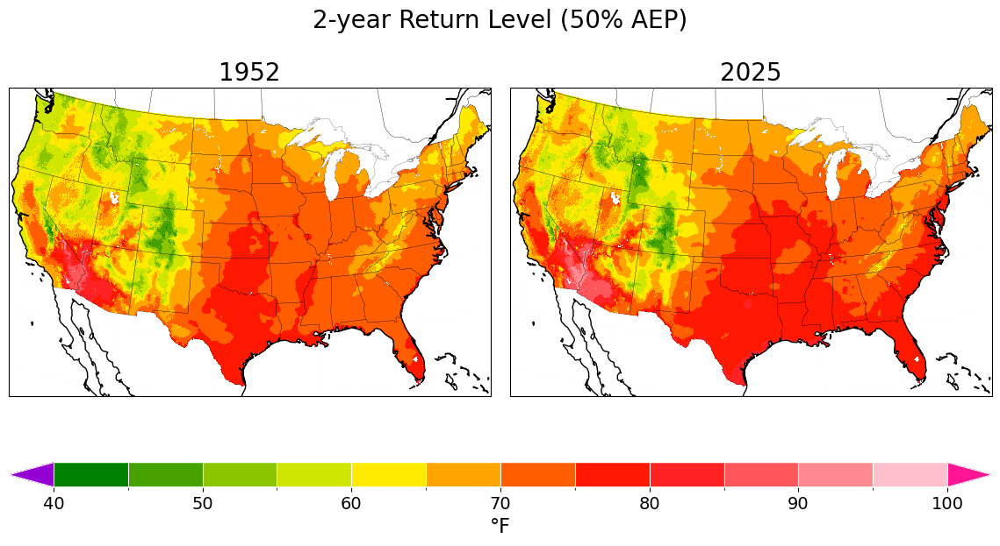

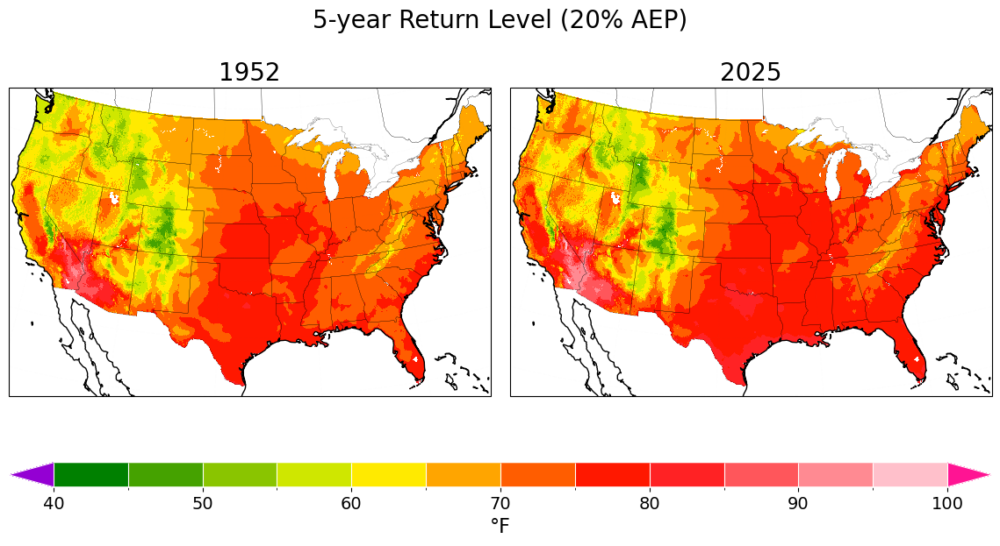

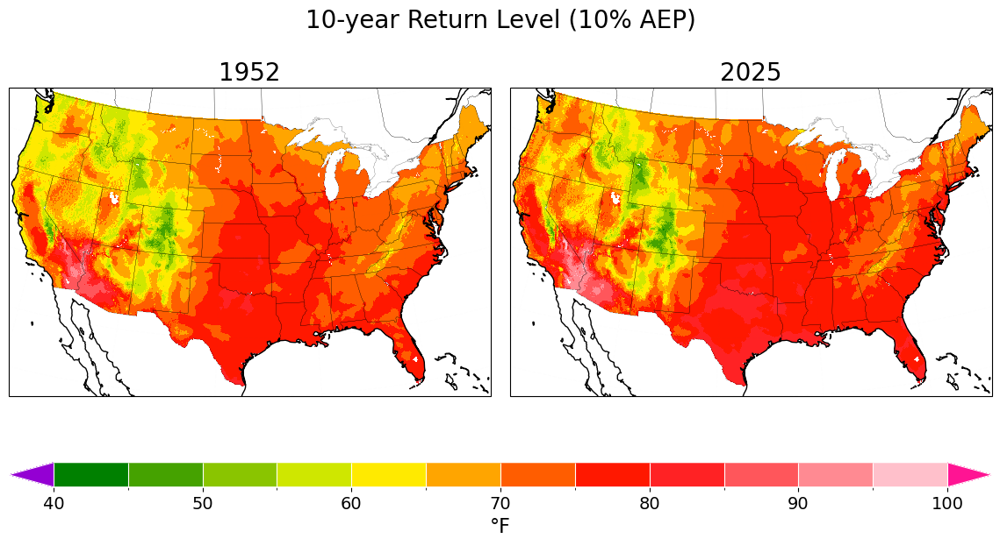

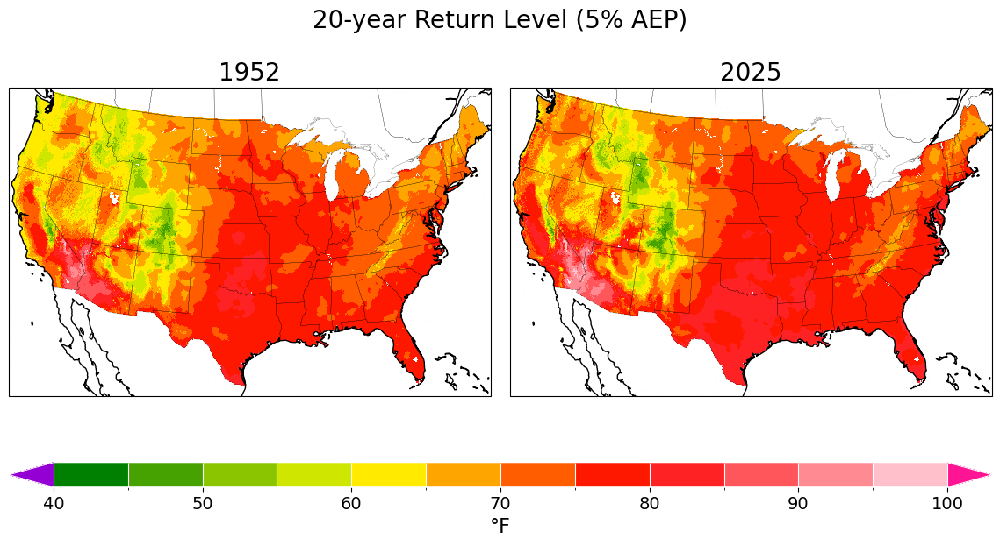

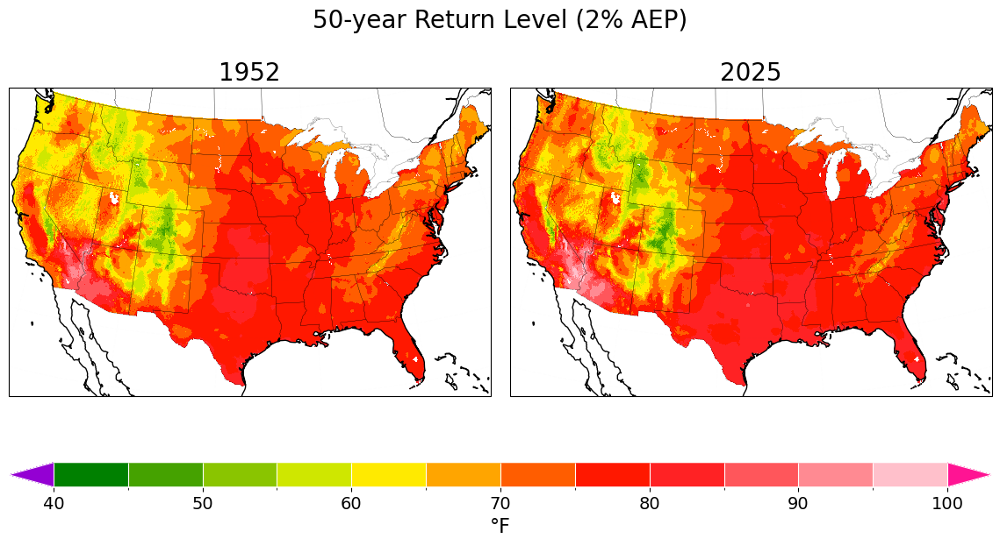

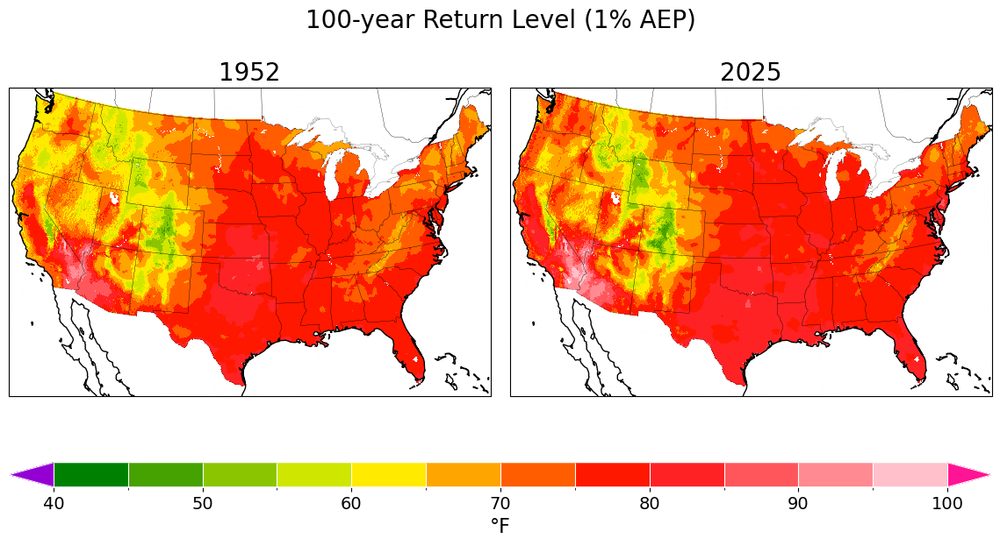

In [144]:

proj=ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

clevs = np.arange(40,105,5)
cmap = plt.get_cmap(cmapI,len(clevs)).copy()
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

for irp in range(0,len(return_periods)):
  fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(14,7),subplot_kw={'projection':proj})

  plt.subplots_adjust(bottom=0.3,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)
  ax = ax.flatten()
  for ix in range(0,len(Tyears)):
    cc = rl.isel(return_periods=irp).sel(time=Tyears[ix]).\
    plot.pcolormesh(ax=ax[ix],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
    ax[ix].set_title(f'{Tyears[ix]}',fontsize=20)  
  ##
  for ix in range(0,len(ax)):
    ####
    grd = ax[ix].gridlines(
      draw_labels=False, 
      color='gray', alpha=0.01, linestyle='--')
    grd.top_labels = False   # Disable top labels
    grd.right_labels = False # Disable right labels. 
    ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
    ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
    ax[ix].coastlines()

  #
  ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])

  cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',drawedges=True,extend='both')
  cbar.ax.tick_params(labelsize=14)  
  cbar.set_label(label=f'{units}',fontsize=16)  
  cbar.outline.set_edgecolor('w')
  cbar.dividers.set_edgecolor('w')
  cbar.dividers.set_linewidth(0.8)

  plt.suptitle(f'{return_periods[irp]}-year Return Level ({AEP[irp]*100:.0f}% AEP)',fontsize=20)  

*Estimated TNx1 return levels in 1952 and 2025 derived from the fitted nonstationary generalized extreme value (GEV) model. Shading indicates the return level (°F) associated with the specified return period. Panels show conditions in 1952 (left) and 2025 (right). Results are presented for return periods ranging from 2 to 100 years.*


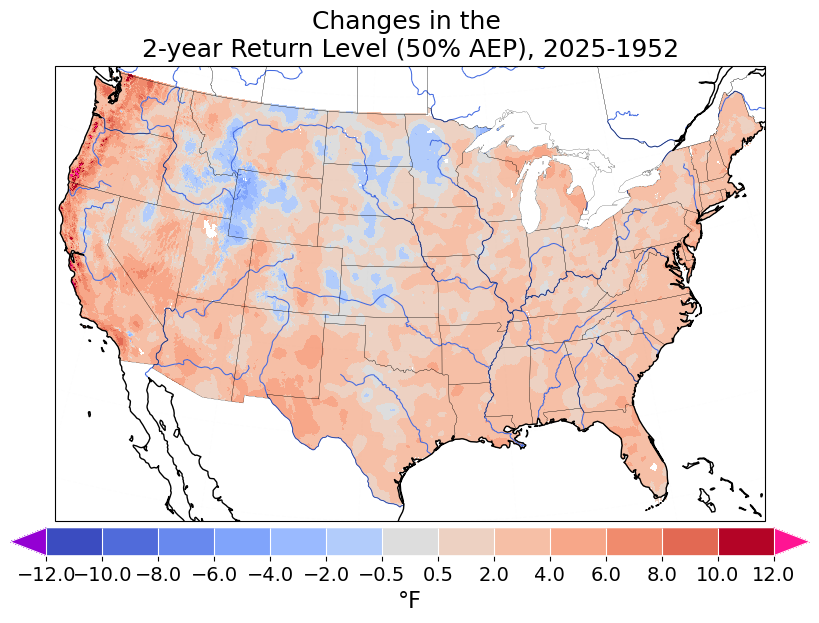

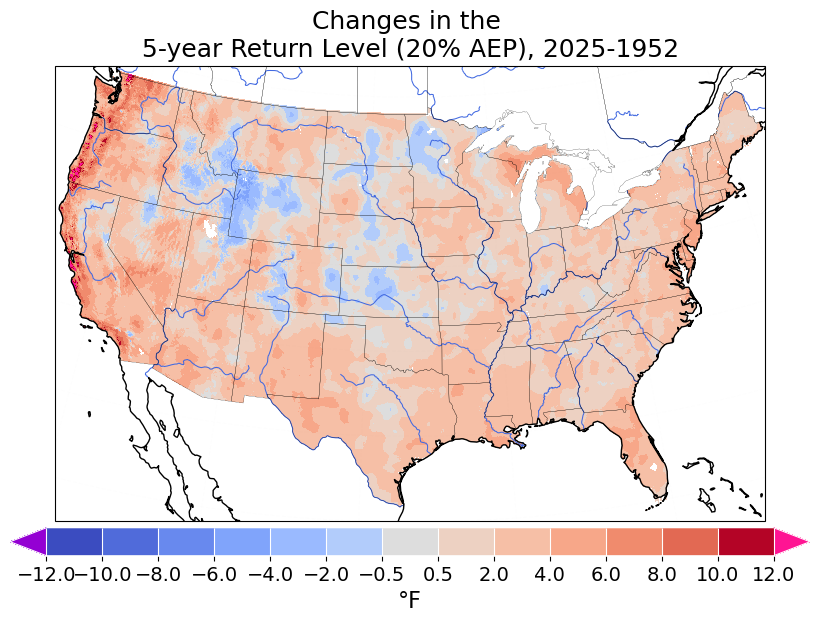

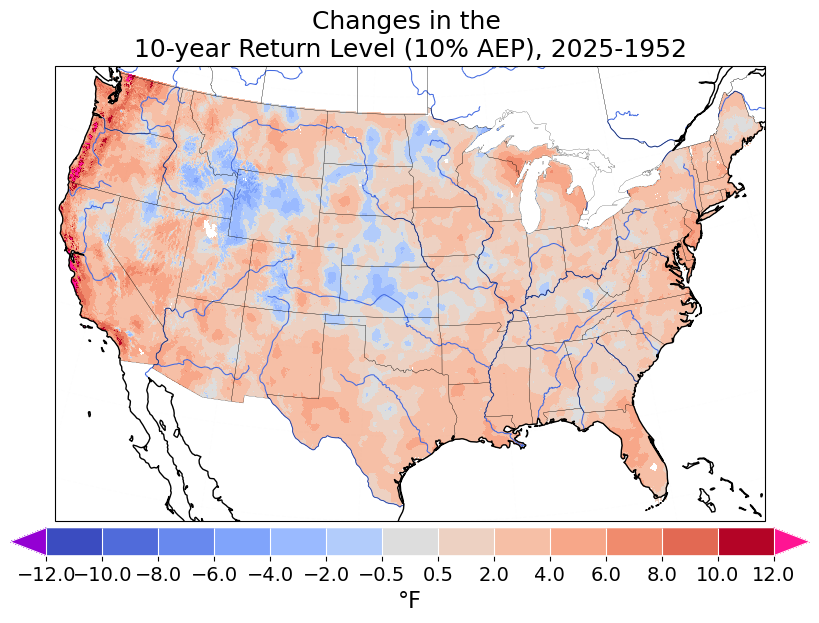

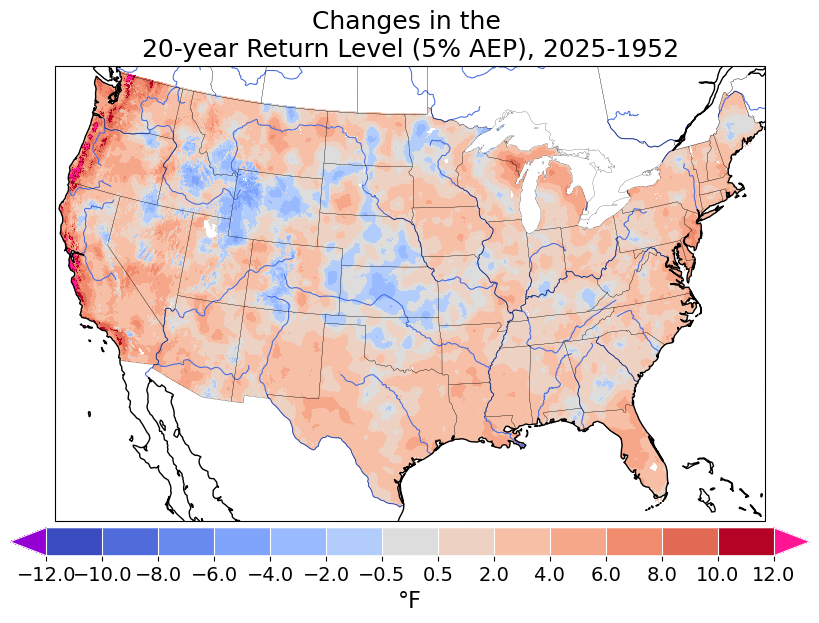

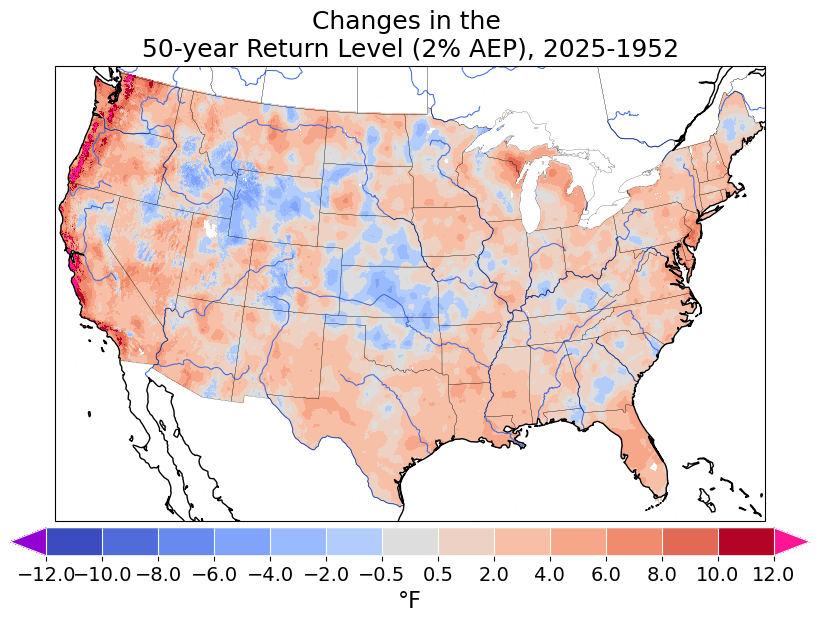

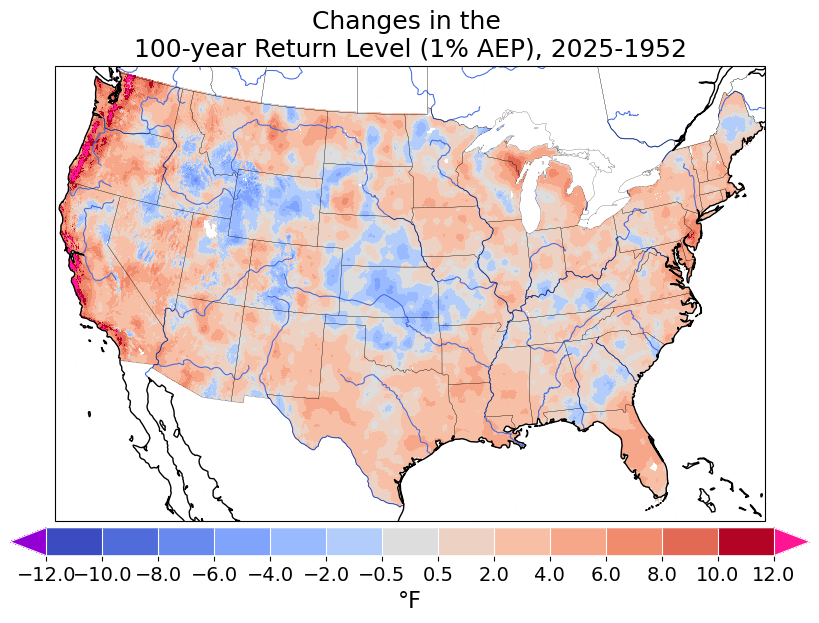

In [145]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

clevst = np.arange(-12,14,2)

clevs= np.concatenate((np.arange(-12,0,2),[-0.5,0.5] ,np.arange(2,14,2)))
cmap = cm.get_cmap(cmapA,len(clevs)+1)
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)
contour_levels = np.arange(0, 4400, 400)

for irp in range(0,len(return_periods)):
  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(10,7),subplot_kw={'projection':proj})
  plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)

  cc = (rl.isel(return_periods=irp).sel(time=Tyears[-1])-rl.isel(return_periods=irp).sel(time=Tyears[0])).\
    plot.pcolormesh(ax=ax,transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
  ax.set_title(f'',fontsize=18)  

  grd = ax.gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax.set_extent((lonW,lonE,latS,latN), crs=proj_data)
  ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax.add_feature(rivers, edgecolor='royalblue', linewidth=0.75)

  ax.coastlines()

  #
  ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
  cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',extend='both',drawedges=True)
  cbar.set_ticks(clevs[:])
  cbar.ax.tick_params(labelsize=14)  
  cbar.set_label(label=f'{units}',fontsize=16)  
  cbar.outline.set_edgecolor('w')
  cbar.dividers.set_edgecolor('w')
  cbar.dividers.set_linewidth(0.8)

  plt.suptitle(f'Changes in the \n{return_periods[irp]}-year Return Level ({AEP[irp]*100:.0f}% AEP), {Tyears[-1]}-{Tyears[0]}',fontsize=18) 

*Changes in TNx1 return levels between 1952 and 2025 estimated from the fitted nonstationary generalized extreme value (GEV) model. Shading indicates the difference in return level ($\Delta RL = RL_{2025} - RL_{1952}$​; °F). Results are shown for return periods ranging from 2 to 100 years.*

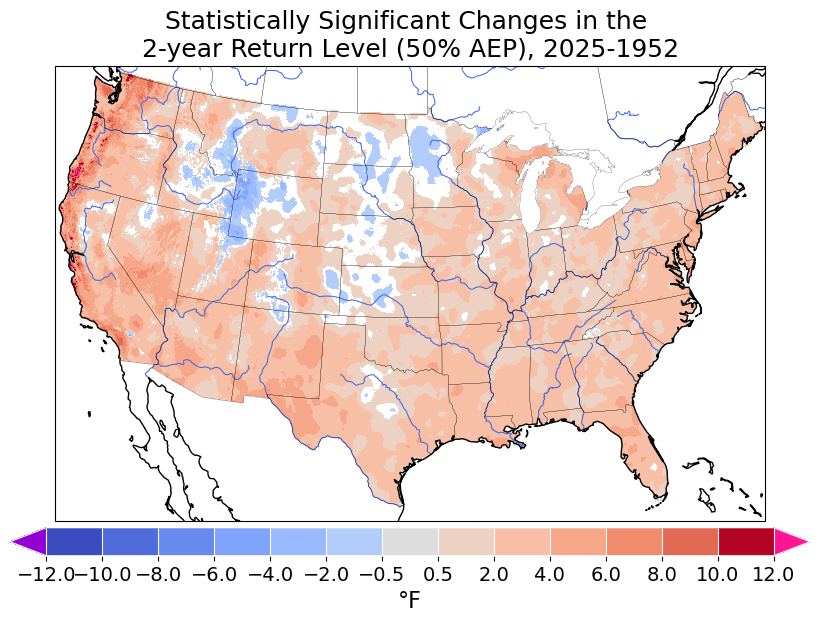

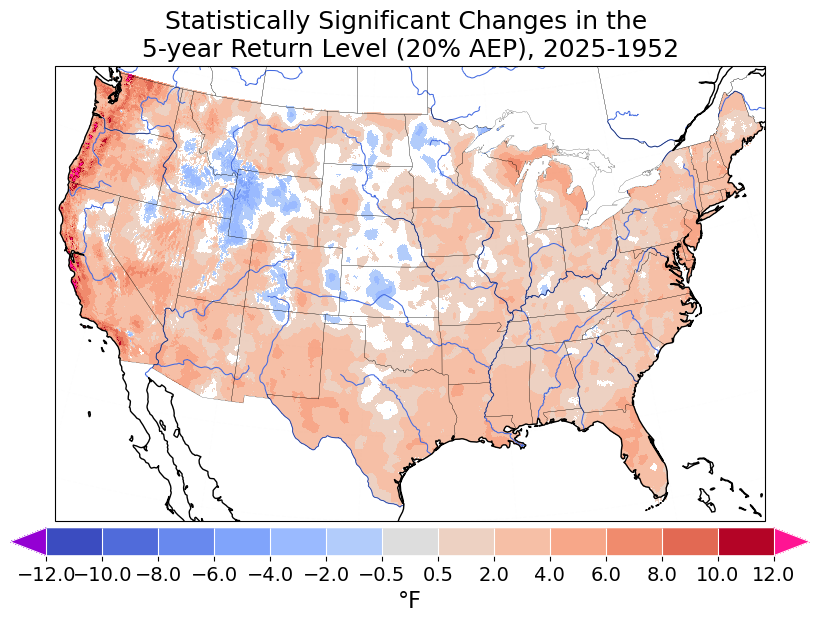

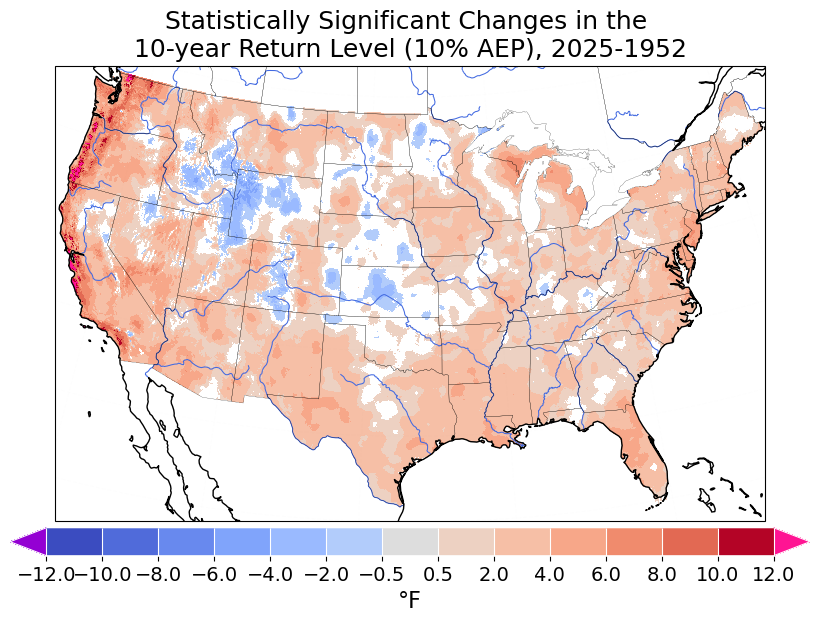

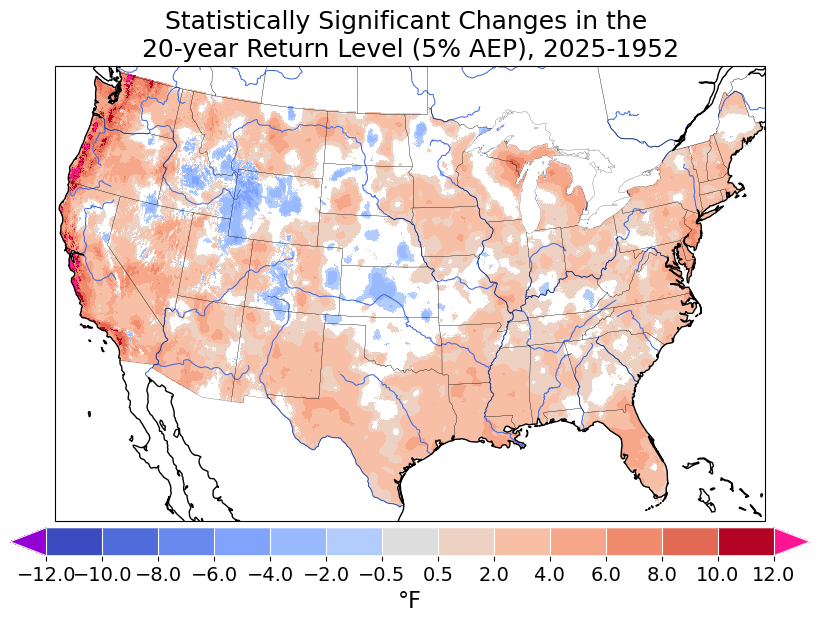

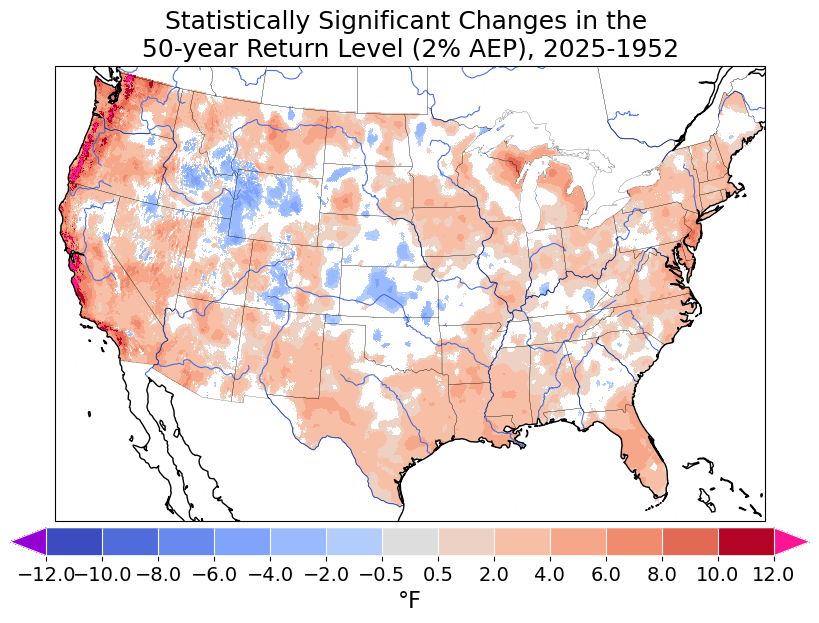

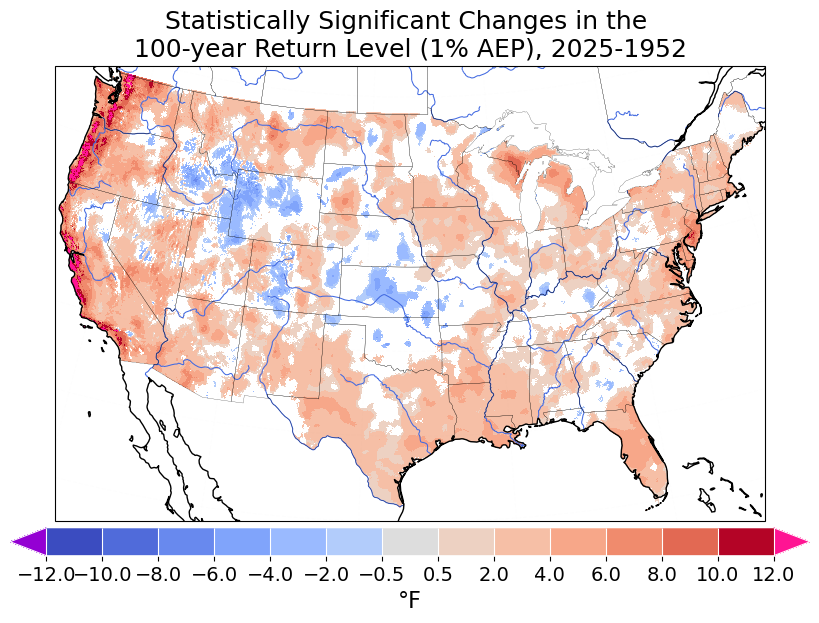

In [146]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

clevst = np.arange(-12,14,2)

clevs= np.concatenate((np.arange(-12,0,2),[-0.5,0.5] ,np.arange(2,14,2)))
cmap = cm.get_cmap(cmapA,len(clevs)+1)
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)
contour_levels = np.arange(0, 4400, 400)

for irp in range(0,len(return_periods)):
  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(10,7),subplot_kw={'projection':proj})
  plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)
  data = rl.isel(return_periods=irp).sel(time=Tyears[-1])
  data = data.where((data > rl_q.isel(return_periods=irp).sel(time=Tyears[0],quantile=0.95)) | (data < rl_q.isel(return_periods=irp).sel(time=Tyears[0],quantile=0.05)) )
  cc = (data-rl.isel(return_periods=irp).sel(time=Tyears[0])).plot.pcolormesh(ax=ax,transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
  ax.set_title(f'',fontsize=18)  

  grd = ax.gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax.set_extent((lonW,lonE,latS,latN), crs=proj_data)
  ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax.add_feature(rivers, edgecolor='royalblue', linewidth=0.75)

  ax.coastlines()

  #
  ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
  cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',extend='both',drawedges=True)
  cbar.set_ticks(clevs[:])
  cbar.ax.tick_params(labelsize=14)  
  cbar.set_label(label=f'{units}',fontsize=16)  
  cbar.outline.set_edgecolor('w')
  cbar.dividers.set_edgecolor('w')
  cbar.dividers.set_linewidth(0.8)

  plt.suptitle(f'Statistically Significant Changes in the \n{return_periods[irp]}-year Return Level ({AEP[irp]*100:.0f}% AEP), {Tyears[-1]}-{Tyears[0]}',fontsize=18) 

*Statistically significant changes in TNx1 return levels between 1952 and 2025 estimated from the fitted nonstationary generalized extreme value (GEV) model. Shading indicates the difference in return level ($\Delta RL = RL_{2025} - RL_{1952}$​; °F). Grid cells are displayed only where the 2025 return level lies outside the 5th to 95th percentile bootstrap confidence interval of the corresponding 1952 return level. Results are shown for return periods ranging from 2 to 100 years.*

In [147]:

## Build colorbar
from matplotlib import cm
clevsa=np.arange(0.05,1.01,0.01)
clevsb=np.arange(0,0.05,0.001)
clevs_pv=np.concatenate((clevsb,clevsa))
cmap = cm.get_cmap('Purples',len(clevsa)+20)
cmaplist = [cmap(i) for i in range(20,cmap.N)]
cmap2 = cm.get_cmap('YlGn_r', len(clevsb)+5)
cmaplist2 = [cmap2(i) for i in range(0,cmap2.N-5)]

pvalue_cmap = mcolors.LinearSegmentedColormap.from_list('Custom cmap',\
                cmaplist2+cmaplist, len(cmaplist2)+len(cmaplist))

Text(0.5, 0.98, 'Likelihood Ratio Test p-Values for Alternative Nonstationary GEV Models')

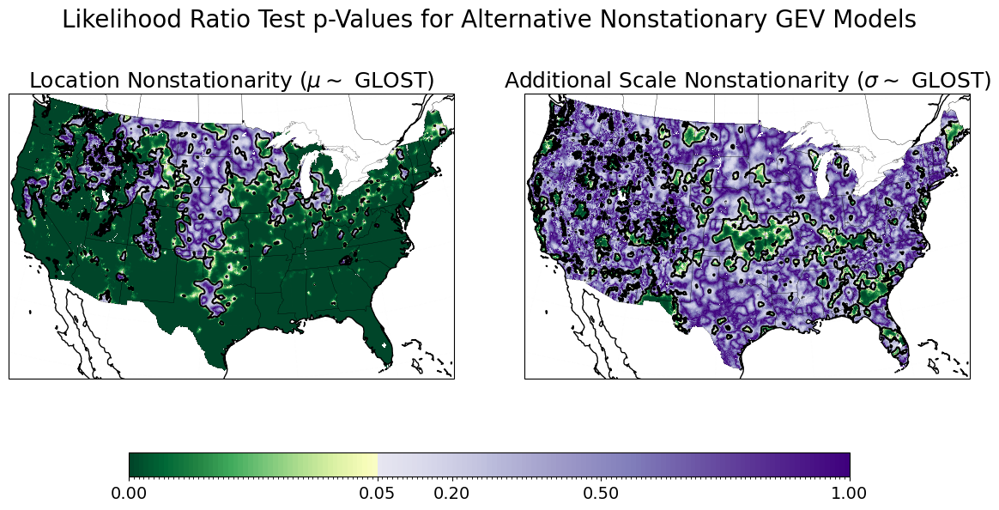

In [148]:
fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(14,7),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.95,hspace=0.04,wspace=0.16)
ax = ax.flatten()
cc = pvalueL.plot.pcolormesh(ax=ax[0],cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),add_colorbar=False)
pvalueL.plot.contour(ax=ax[0],colors='k',levels=[0,0.1],transform=ccrs.PlateCarree(),add_colorbar=False)
ax[0].set_title(r'Location Nonstationarity ($\mu \sim$ GLOST)',fontsize=18)  
cc = pvalueS.plot.pcolormesh(ax=ax[1],cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),add_colorbar=False)
pvalueS.plot.contour(ax=ax[1],colors='k',levels=[0,0.1],transform=ccrs.PlateCarree(),add_colorbar=False)
ax[1].set_title(r'Additional Scale Nonstationarity ($\sigma \sim$ GLOST)',fontsize=18)  

for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()

#
ax_cbar = fig.add_axes([0.2, 0.2, 0.6, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=[0,0.05,0.2,0.5,1])
cbar.ax.tick_params(labelsize=14)  
cbar.set_label(label='',fontsize=16)
#

plt.suptitle(f'Likelihood Ratio Test p-Values for Alternative Nonstationary GEV Models',fontsize=20)  

*Spatial distribution of likelihood ratio test p-values for successive nonstationary GEV model formulations of TNx1. The left panel shows p-values for the comparison between a stationary model and a model with a GLOST-dependent location parameter ($\mu \sim \text{GLOST}$). The right panel shows p-values for the comparison between the location-only nonstationary model and a model with both location and scale parameters dependent on GLOST (μ,$\sigma \sim \text{GLOST}$). Lower p-values indicate stronger statistical support for including the additional covariate effect. Black contours delineate regions where $p \le 0.10$.*

Text(0.5, 0.98, 'Spatial Distribution of the GEV Location Parameter')

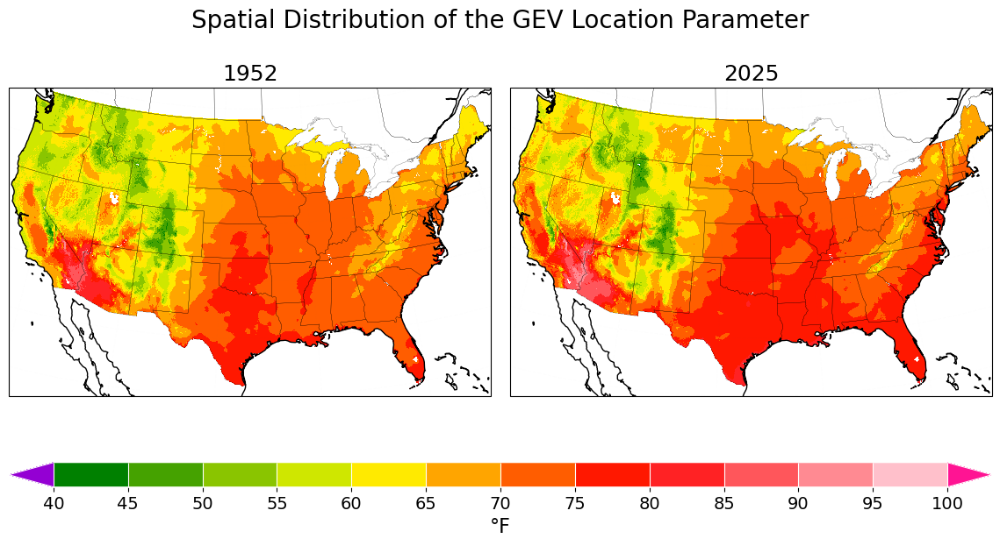

In [149]:
clevs = np.arange(40,105,5)
cmap = plt.get_cmap(cmapI,len(clevs)).copy()
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(14,7),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.3,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)
cc = location.sel(time=yearb).plot.pcolormesh(ax=ax[0],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[0].set_title(yearb,fontsize=18)    
location.sel(time=yeare).plot.pcolormesh(ax=ax[1],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[1].set_title(yeare,fontsize=18)    

####
for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()

#
#
ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=clevs[:],drawedges=True,extend='both')
cbar.set_label(label=units,fontsize=16)
cbar.ax.tick_params(labelsize=14)  
cbar.outline.set_edgecolor('w')
cbar.dividers.set_edgecolor('w')
cbar.dividers.set_linewidth(0.8)
plt.suptitle(f'Spatial Distribution of the GEV Location Parameter',fontsize=20)  

*Spatial distribution of the estimated GEV location parameter ($\mu$) for TNx1 in 1952 (left) and 2025 (right). The location parameter describes the central tendency of the extreme-value distribution, with larger values corresponding to higher extreme temperatures. Differences between the two periods illustrate shifts in the magnitude of temperature extremes across the study domain. Units are °F.*

Text(0.5, 0.98, 'Change in the GEV Location Parameter,\n2025-1952')

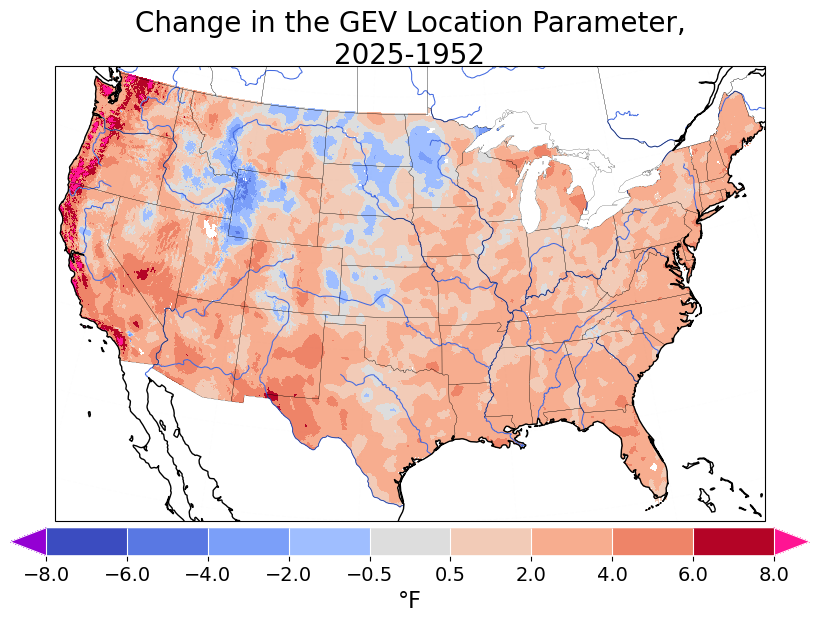

In [150]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

clevst = np.arange(-8,10,2)
clevs= np.concatenate((np.arange(-8,0,2),[-0.5,0.5] ,np.arange(2,10,2)))
cmap = cm.get_cmap(cmapA,len(clevs)+1)
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(10,7),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)

cc = (location.sel(time=Tyears[-1])-location.sel(time=Tyears[0])).\
  plot.pcolormesh(ax=ax,transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
##

####
grd = ax.gridlines(
  draw_labels=False, 
  color='gray', alpha=0.01, linestyle='--')
grd.top_labels = False   # Disable top labels
grd.right_labels = False # Disable right labels. 
ax.set_extent((lonW,lonE,latS,latN), crs=proj_data)
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)  
ax.add_feature(rivers, edgecolor='royalblue', linewidth=0.75)

ax.coastlines()

#
ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',extend='both',drawedges=True)
cbar.set_ticks(clevs[:])
cbar.ax.tick_params(labelsize=14)  
cbar.set_label(label=f'{units}',fontsize=16)
cbar.outline.set_edgecolor('w')
cbar.dividers.set_edgecolor('w')
cbar.dividers.set_linewidth(0.8)
plt.suptitle(f'Change in the GEV Location Parameter,\n{Tyears[-1]}-{Tyears[0]}',fontsize=20)  

*Spatial distribution of the change in the estimated GEV location parameter ($\mu$) for TNx1 between 1952 and 2025. Shading indicates $\Delta\mu = \mu_{2025} - \mu_{1952}$​ (°F). Positive values denote higher values of the location parameter in 2025, indicating a shift toward warmer extreme temperature events, while negative values denote lower values.*

Text(0.5, 0.98, 'Spatial Distribution of the GEV Scale Parameter')

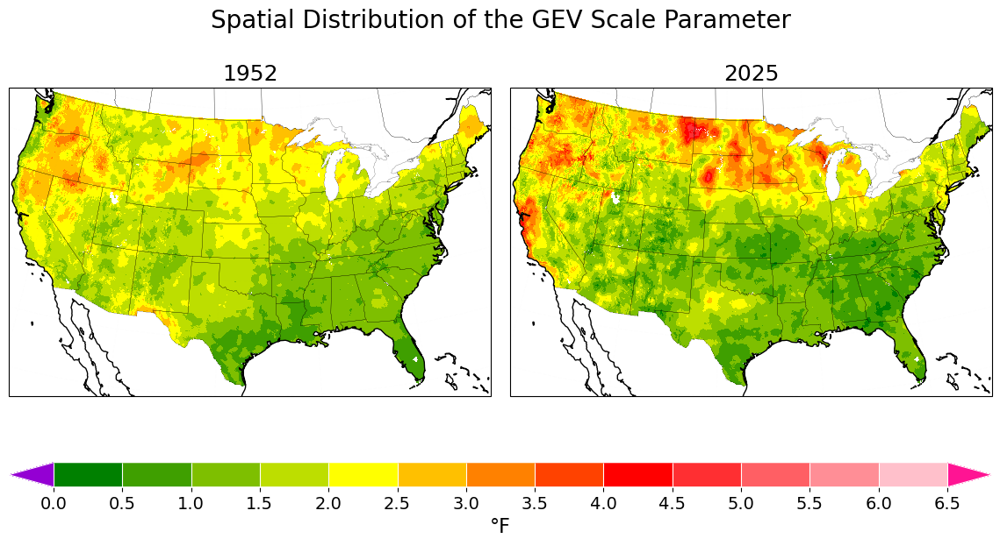

In [151]:

clevs = np.arange(0,7,0.5)
cmap = plt.get_cmap(cmapI,len(clevs)).copy()
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(14,7),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.3,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)
cc = scale.sel(time=yearb).plot.pcolormesh(ax=ax[0],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[0].set_title(yearb,fontsize=18)    
scale.sel(time=yeare).plot.pcolormesh(ax=ax[1],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[1].set_title(yeare,fontsize=18)    

####
for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()

#
#
ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=clevs[:],drawedges=True,extend='both')
cbar.set_label(label=units,fontsize=16)
cbar.ax.tick_params(labelsize=14)  
cbar.outline.set_edgecolor('w')
cbar.dividers.set_edgecolor('w')
cbar.dividers.set_linewidth(0.8)
plt.suptitle(f'Spatial Distribution of the GEV Scale Parameter',fontsize=20)  

*Spatial distribution of the estimated scale parameter ($\sigma$) of the nonstationary generalized extreme value (GEV) model for TNx1 in 1952 (left) and 2025 (right). The scale parameter describes the spread of the extreme-value distribution, with larger values indicating greater variability in extreme temperature events. Spatial and temporal variations in $\sigma$ reflect changes in the dispersion of TNx1 extremes across the study domain. Units are °F.*

Text(0.5, 0.98, 'Spatial Distribution of the GEV Shape Parameter')

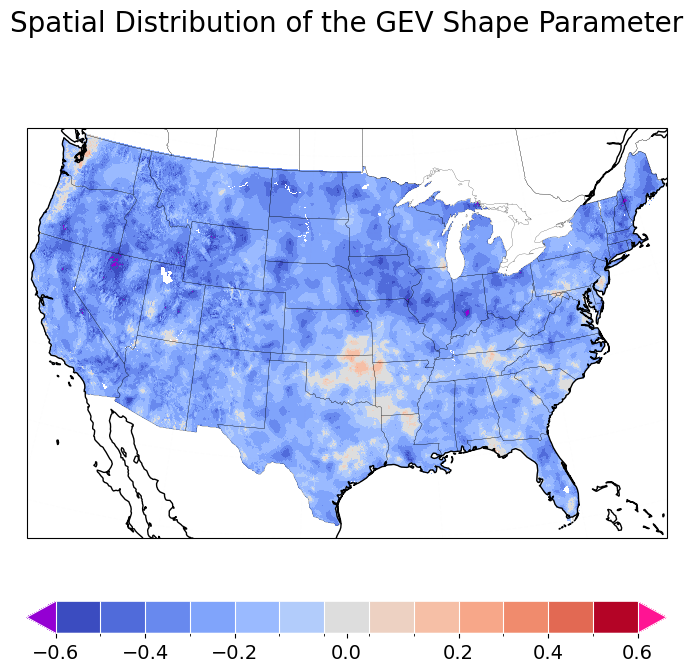

In [152]:
clevst = np.arange(-0.6,0.8,0.1)
clevs= np.concatenate((np.arange(-0.6,0,0.1),[-0.05,0.05] ,np.arange(0.1,0.7,0.1)))
cmap = cm.get_cmap(cmapA,len(clevs)+1)
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()
fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(8,8),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.9,hspace=0.04,wspace=0.16)
cc = shape.sel(time=yeare).plot.pcolormesh(ax=ax,cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax.set_title('',fontsize=18) 
####

####
grd = ax.gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
grd.top_labels = False   # Disable top labels
grd.right_labels = False # Disable right labels. 
ax.set_extent((lonW,lonE,latS,latN), crs=proj_data)
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()
#
#
ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=clevst[::2],drawedges=True,extend='both')
cbar.ax.tick_params(labelsize=14)  
cbar.outline.set_edgecolor('w')
cbar.dividers.set_edgecolor('w')
cbar.dividers.set_linewidth(0.8)
plt.suptitle(f'Spatial Distribution of the GEV Shape Parameter',fontsize=20)  

*Spatial distribution of the estimated GEV shape parameter ($\xi$) for TNx1. The shape parameter controls the behavior of the upper tail of the extreme-value distribution, with positive values indicating heavier tails, negative values indicating bounded tails, and values near zero corresponding to a Gumbel-type distribution. Because $\xi$ is assumed constant through time, only a single spatial field is shown. The shape parameter is dimensionless.*

Text(0.5, 0.98, 'Time-Averaged Cross-Validation Performance Metrics')

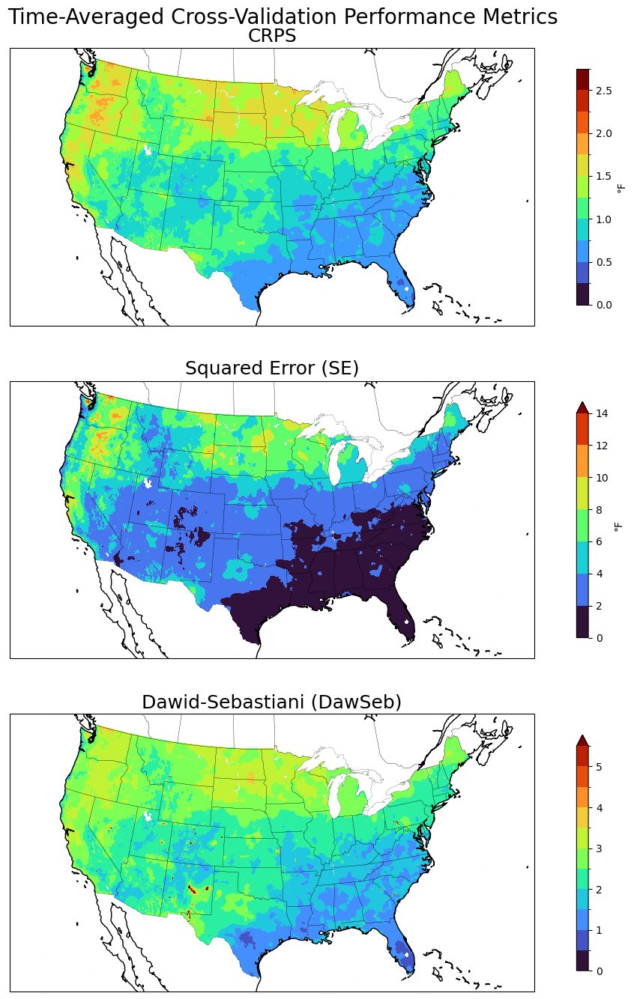

In [153]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

fig, ax = plt.subplots(nrows=3,ncols=1,figsize=(14,18),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.95,hspace=0.2,wspace=0.02)

ax = ax.flatten()
clevs = np.arange(0,3,0.25)
cc = CRPS_cv.mean('time').plot.pcolormesh(ax=ax[0],cmap='turbo',levels=clevs,transform=ccrs.PlateCarree(),cbar_kwargs={'shrink':0.85,'label':units})
ax[0].set_title(f'CRPS',fontsize=18)  
clevs = np.arange(0,16,2)
cc = SE_cv.mean('time').plot.pcolormesh(ax=ax[1],cmap='turbo',levels=clevs,transform=ccrs.PlateCarree(),cbar_kwargs={'shrink':0.85,'label':units})
ax[1].set_title(f'Squared Error (SE)',fontsize=18)  
clevs = np.arange(0,6,0.5)
cc = DawSeb_cv.mean('time').plot.pcolormesh(ax=ax[2],cmap='turbo',levels=clevs,transform=ccrs.PlateCarree(),cbar_kwargs={'shrink':0.85,'label':''})
ax[2].set_title(f'Dawid-Sebastiani (DawSeb)',fontsize=18)  

for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()
#
plt.suptitle(f'Time-Averaged Cross-Validation Performance Metrics',fontsize=20)  

*Time-averaged cross-validation performance metrics for the nonstationary GEV model. Shown are the mean Continuous Ranked Probability Score (CRPS), Squared Error (SE), and Dawid-Sebastiani Score (DawSeb) computed across all validation years. These metrics evaluate the agreement between cross-validated model predictions and observations, with lower values indicating better predictive performance. CRPS assesses the accuracy of the full predictive distribution, SE measures error in the predicted central estimate, and the Dawid-Sebastiani score jointly evaluates calibration and sharpness of the predictive distribution.*

Text(0.5, 0.98, 'Time-Averaged Cross-Validation Goodness-of-Fit p-Values')

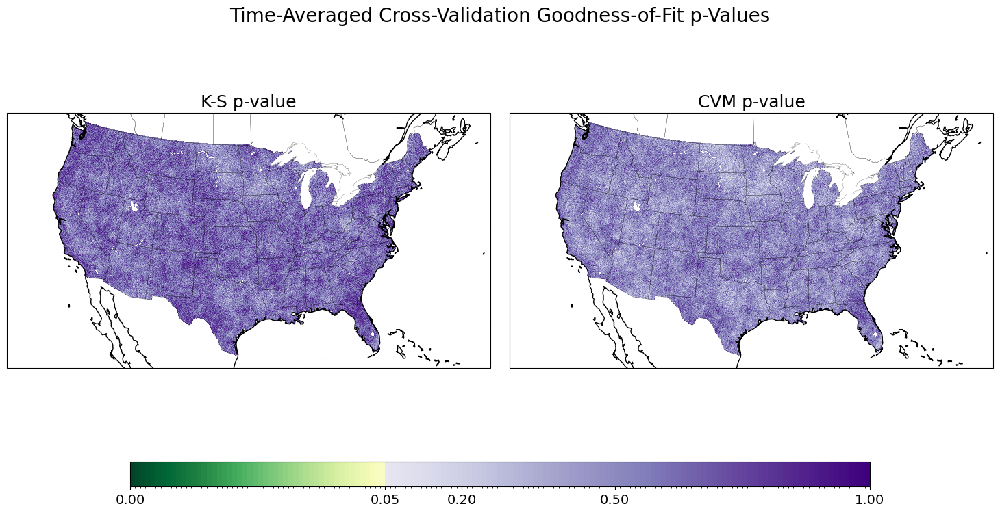

In [154]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(18,9),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.95,hspace=0.04,wspace=0.04)
ax = ax.flatten()
cc = KS_pvalue_cv.mean('time').plot.pcolormesh(ax=ax[0],cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[0].set_title(f'K-S p-value',fontsize=18)  
cc = CVM_pvalue_cv.mean('time').plot.pcolormesh(ax=ax[1],cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[1].set_title(f'CVM p-value',fontsize=18)  

for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()

ax_cbar = fig.add_axes([0.2, 0.2, 0.6, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=[0,0.05,0.2,0.5,1])
cbar.ax.tick_params(labelsize=14)   
#
plt.suptitle(f'Time-Averaged Cross-Validation Goodness-of-Fit p-Values',fontsize=20)  

*Spatial distribution of mean cross-validation p-values for the nonstationary GEV model, averaged over all validation years. Panels show results from the Kolmogorov-Smirnov (K-S) and Cramér-von Mises (CVM) goodness-of-fit tests. Higher p-values indicate better model performance, while values below 0.05 suggest that the modeled and observed distributions differ significantly.*

In [155]:
Tquantile=['0.95','0.05']
vq=[float(x) for x in Tquantile]

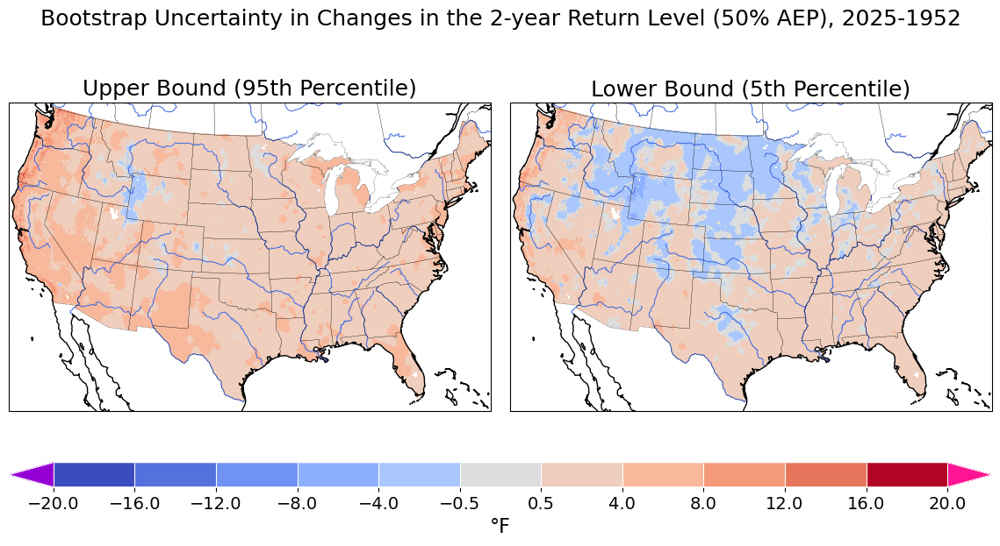

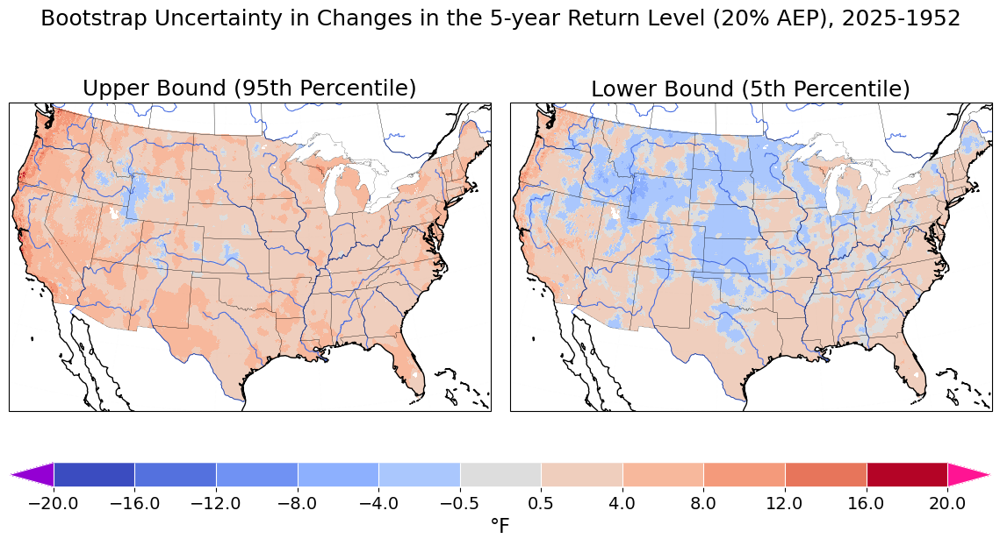

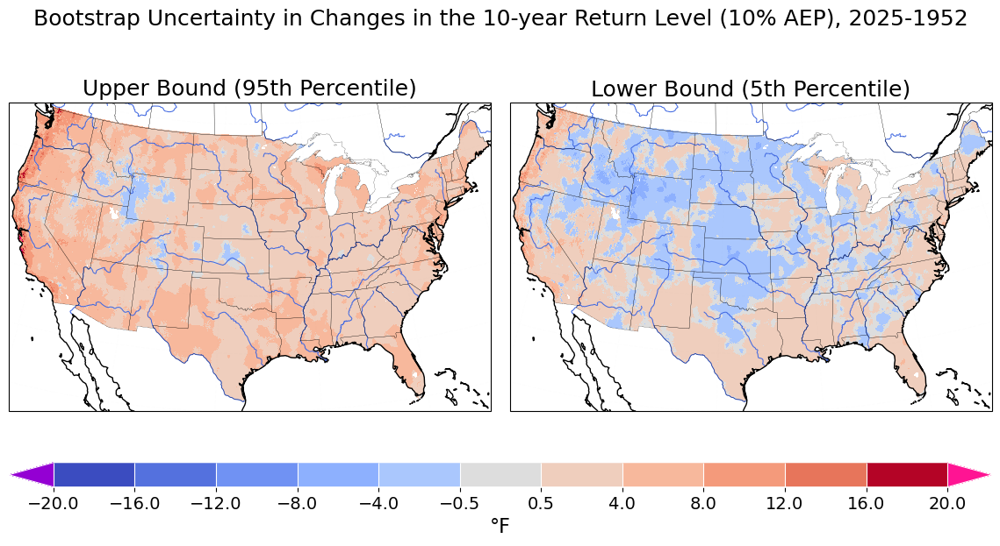

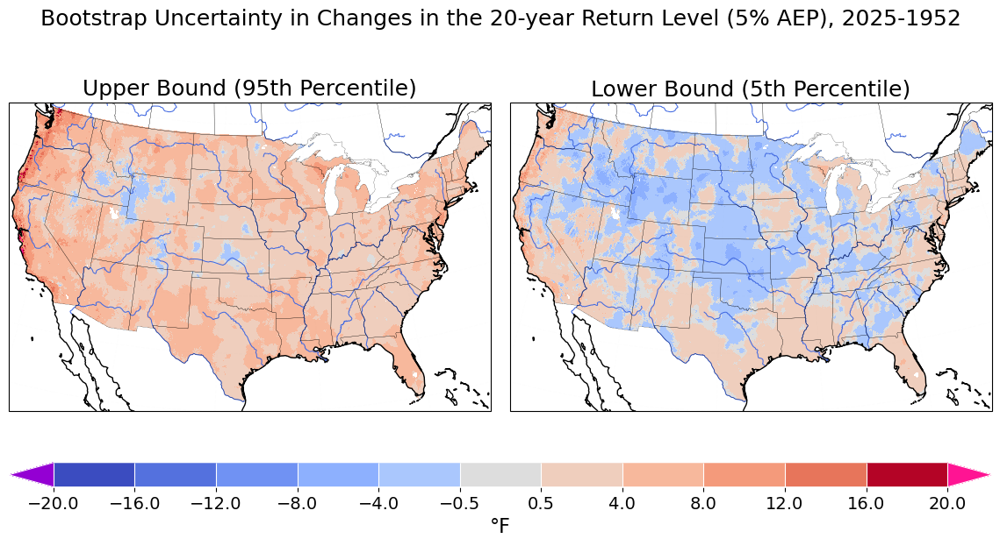

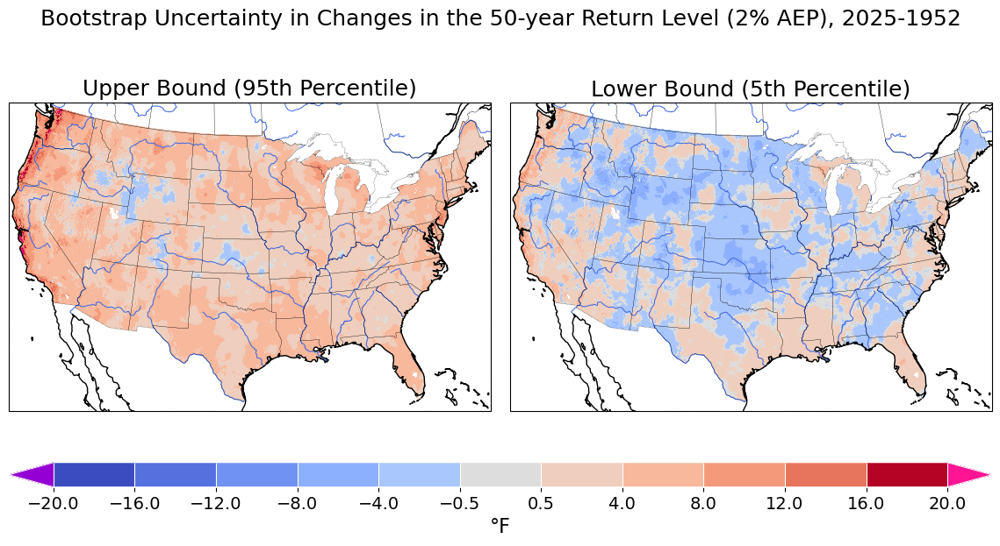

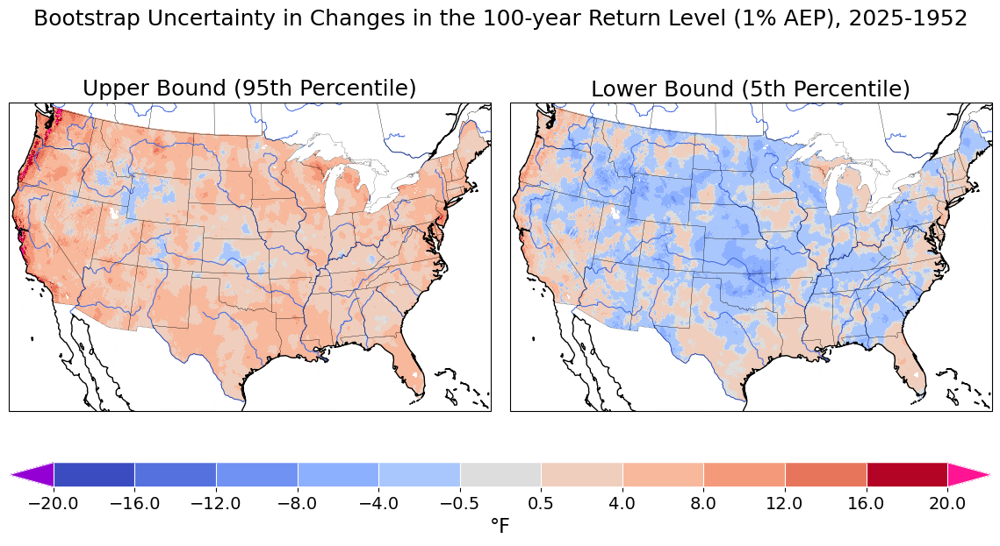

In [156]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

clevst = np.arange(-20,24,4)

clevs= np.concatenate((np.arange(-20,0,4),[-0.5,0.5] ,np.arange(4,24,4)))
cmap = cm.get_cmap(cmapA,len(clevs)+1)
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

for irp in range(0,len(return_periods)):
  fig, ax = plt.subplots(nrows=1,ncols=len(Tquantile),figsize=(14,7),subplot_kw={'projection':proj})
  plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)

  for ix in range(0,len(Tquantile)):
    cc = Diffrl_q.sel(quantile=vq[ix]).isel(return_periods=irp).plot.pcolormesh\
    (ax=ax[ix],transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
    if Tquantile[ix] == '0.05':
      ax[ix].set_title(f'Lower Bound (5th Percentile)',fontsize=18)
    elif Tquantile[ix] == '0.95': 
      ax[ix].set_title(f'Upper Bound (95th Percentile)',fontsize=18)   
    ##

    ####
    grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
    grd.top_labels = False   # Disable top labels
    grd.right_labels = False # Disable right labels. 
    ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
    ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
    ax[ix].add_feature(rivers, edgecolor='royalblue', linewidth=0.75)
    ax[ix].coastlines()

  #
  ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
  cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',extend='both', drawedges=True)
  cbar.set_ticks(clevs[:])
  cbar.ax.tick_params(labelsize=14)  
  cbar.set_label(label=f'{units}',fontsize=16)
  cbar.outline.set_edgecolor('w')
  cbar.dividers.set_edgecolor('w')
  cbar.dividers.set_linewidth(0.8)

  plt.suptitle(f'Bootstrap Uncertainty in Changes in the {return_periods[irp]}-year Return Level ({AEP[irp]*100:.0f}% AEP), {yeare}-{yearb}',fontsize=18)  

*Bootstrap uncertainty in changes in TNx1 return levels between 1952 and 2025 derived from the fitted nonstationary GEV model. Shading shows the change in return level ($\Delta RL = RL_{2025} - RL_{1952}$​; °F) for the 5th, and 95th percentiles of the bootstrap distribution. Results are presented for the indicated return period. Positive values indicate higher return levels in 2025 relative to 1952, while negative values indicate lower return levels.*

## Step 4: Timeseries

In [157]:
ptlon = [-122.10416646, -111.02083224, -105.02083176, -102.27083154, -96.7708311, -91.7708307, -87.77083038, -80.77082982, -74.02082928]
ptlat = [37.72916772, 32.22916728, 39.72916788, 43.97916822, 46.72916844, 41.97916806, 41.72916804, 35.22916752, 40.72916796]
Tcity = ['SanFransisco','Tucson','Denver','Wall','Fargo','CedarRapids','Chicago','Charlotte','NYC']

In [158]:
CB_color = ['#377eb8', '#ff7f00', '#4daf4a',\
            '#e41a1c', '#a65628', '#984ea3',\
            '#999999', '#f781bf', '#dede00']

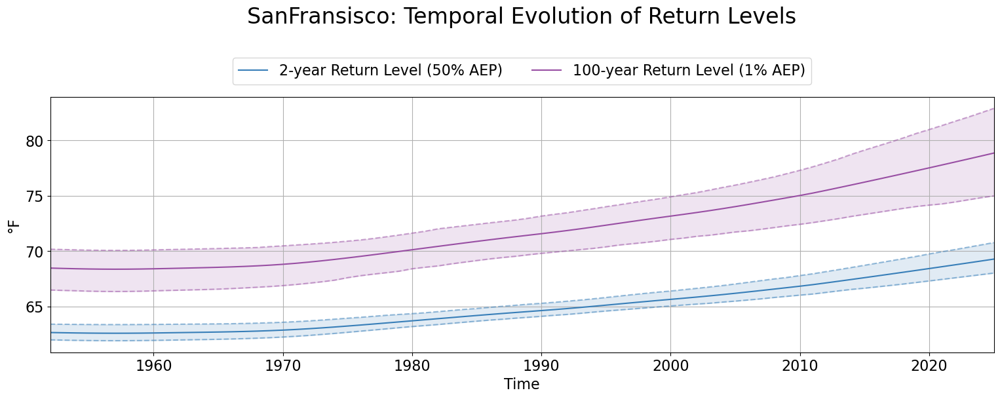

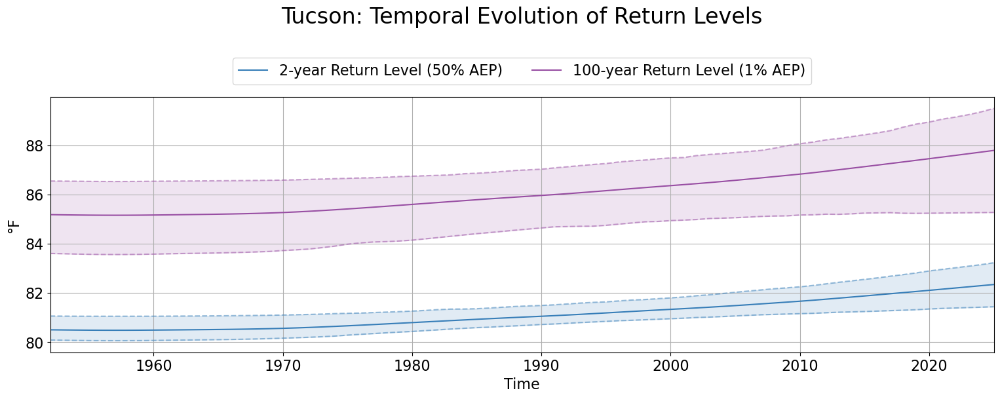

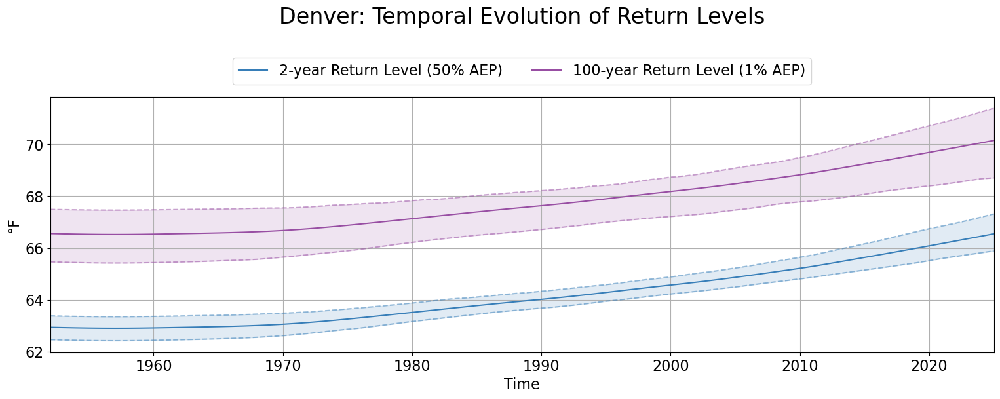

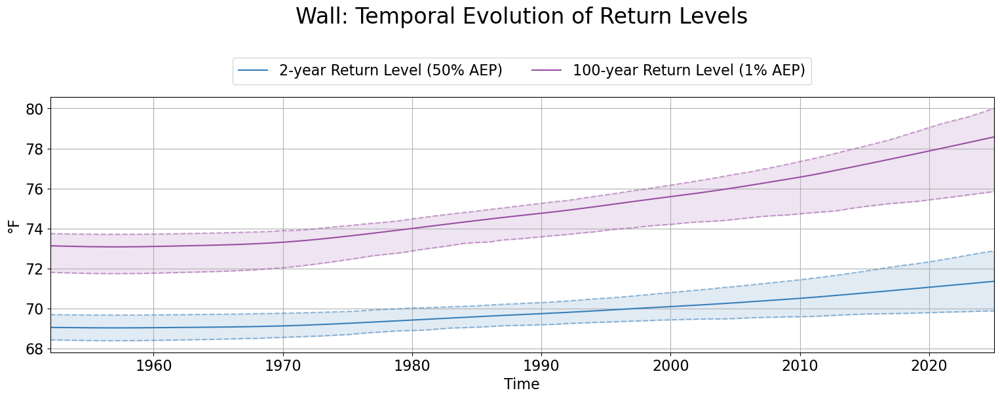

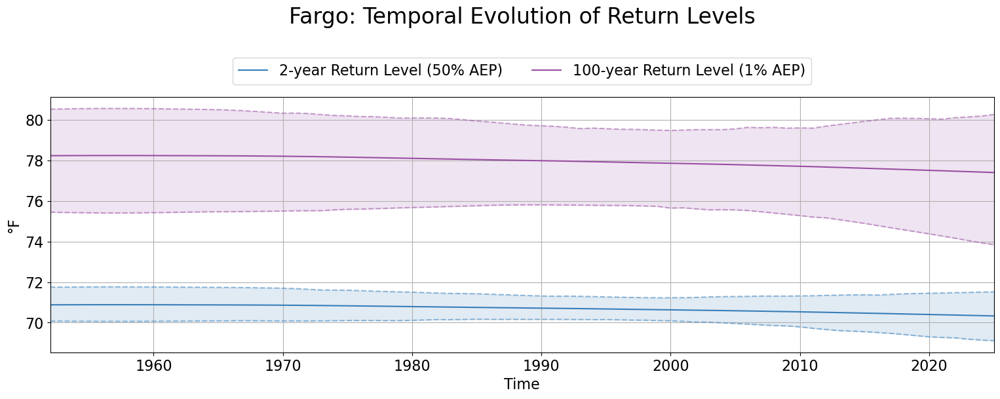

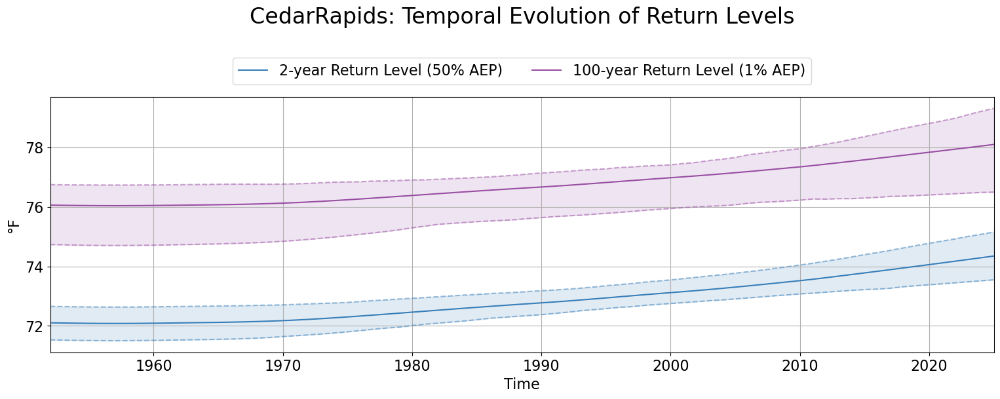

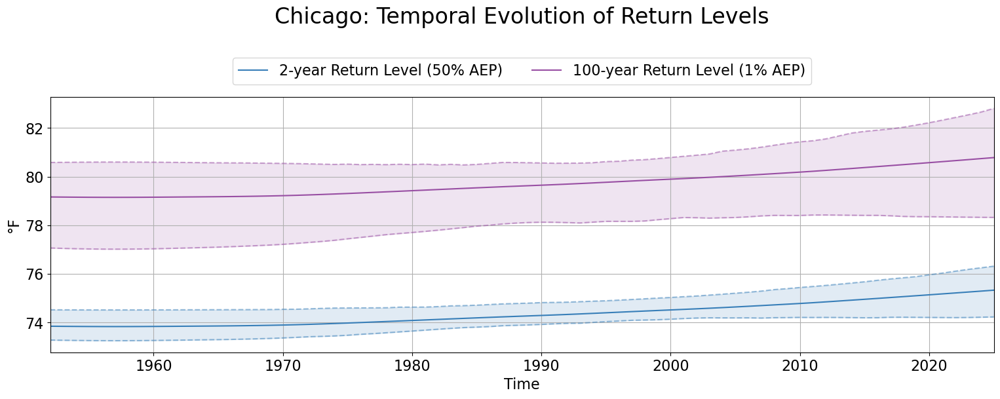

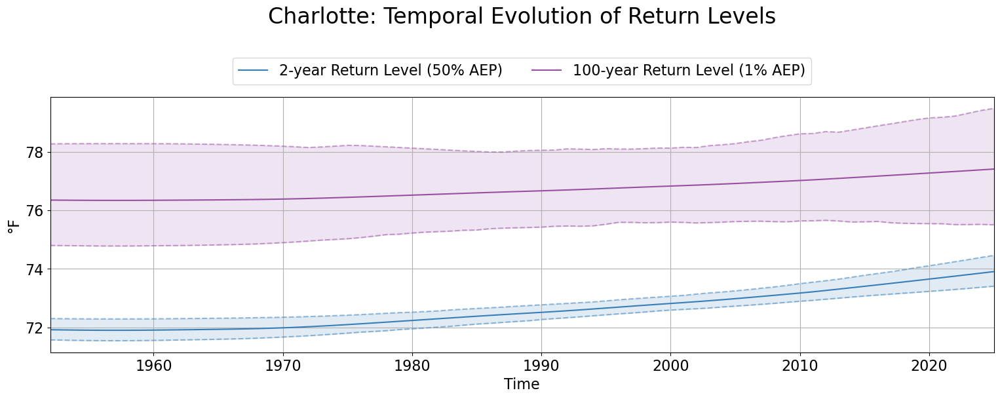

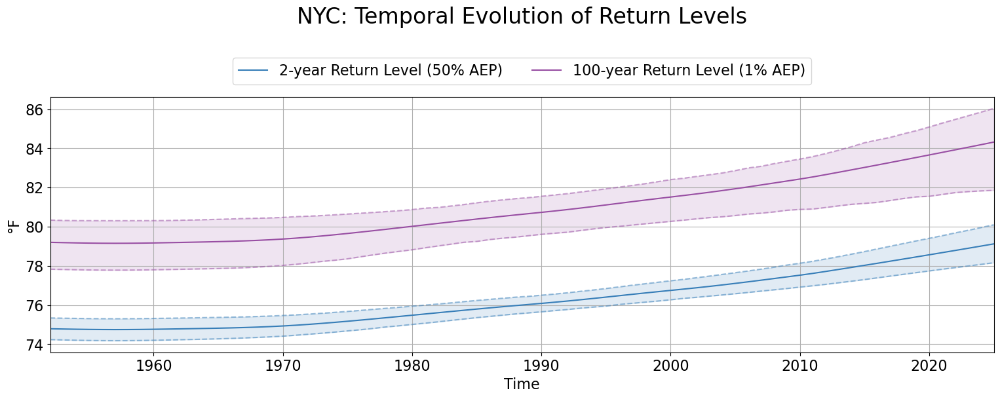

In [159]:
for ic in range(len(Tcity)):

  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(18,6))
  plt.subplots_adjust(bottom=0.1,left=0.1, right=0.9,top=0.75,wspace=0.2)

  for irp in [0,len(return_periods)-1]:
    label = f'{return_periods[irp]}-year Return Level ({AEP[irp]*100:.0f}% AEP)'
    ax.plot(ds['time'],rl.sel(lon=ptlon[ic],lat=ptlat[ic],return_periods=return_periods[irp]),color=CB_color[irp],label=label)
    ax.plot(ds['time'],rl_q.sel(lon=ptlon[ic],lat=ptlat[ic],return_periods=return_periods[irp],quantile=0.95),color=CB_color[irp],ls='--',alpha=0.5)
    ax.plot(ds['time'],rl_q.sel(lon=ptlon[ic],lat=ptlat[ic],return_periods=return_periods[irp],quantile=0.05),color=CB_color[irp],ls='--',alpha=0.5)
    ax.fill_between(ds['time'],rl_q.sel(lon=ptlon[ic],lat=ptlat[ic],return_periods=return_periods[irp],quantile=0.05),\
      rl_q.sel(lon=ptlon[ic],lat=ptlat[ic],return_periods=return_periods[irp],quantile=0.95),color=CB_color[irp],alpha=0.15)
     
  ax.tick_params(labelsize=16)
  ax.grid(True)
  ax.set_ylabel(f'{units}',fontsize=16) 
  ax.set_xlim(ds['time'][0],ds['time'][-1]) 
  ax.set_xlabel('Time',fontsize=16)
  plt.legend(loc='center',ncol=len(return_periods),bbox_to_anchor=(0.5,1.1),fontsize=16)

  #plt.legend(loc='center',ncol=len(return_periods),bbox_to_anchor=(-0.12,1.05),fontsize=12)
  plt.suptitle(f'{Tcity[ic]}: Temporal Evolution of Return Levels',fontsize=24)
  plt.show()

*Time series of the estimated 2-year and 100-year return levels of TNx1 derived from the nonstationary generalized extreme value (GEV) model for selected cities during 1952-2025. Solid lines show the fitted return levels, and shaded regions denote the corresponding 5th to 95th percentile bootstrap confidence intervals. The 2-year return level represents relatively common extreme temperature events, whereas the 100-year return level represents rare and exceptionally extreme events. Their temporal evolution reflects changes in the magnitude and frequency of temperature extremes across the study period. Units are °F.*

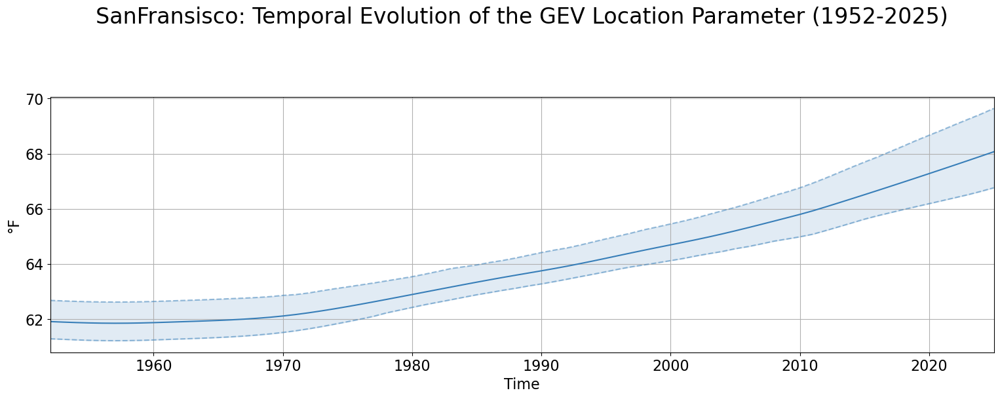

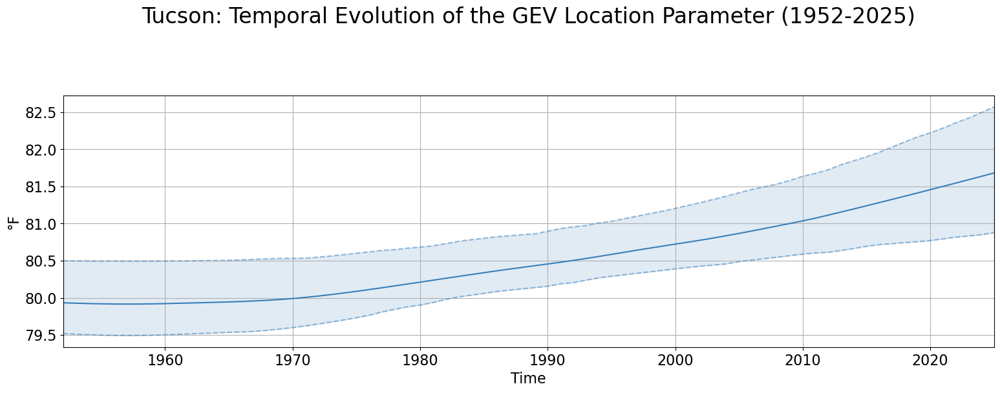

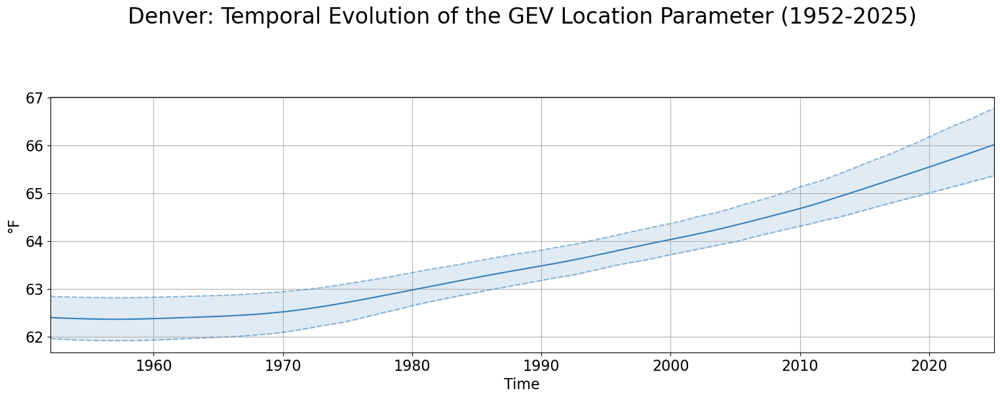

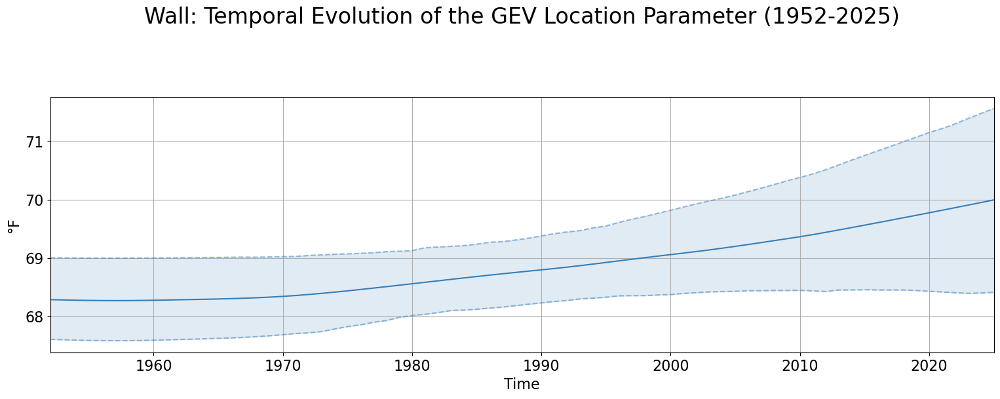

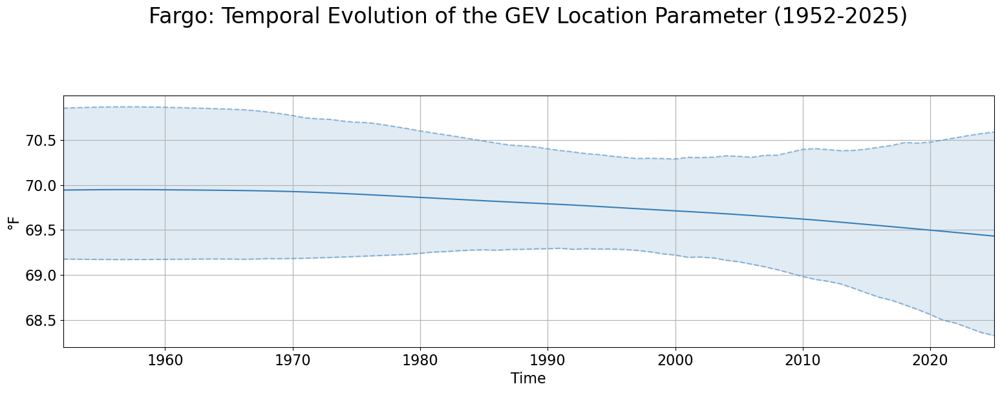

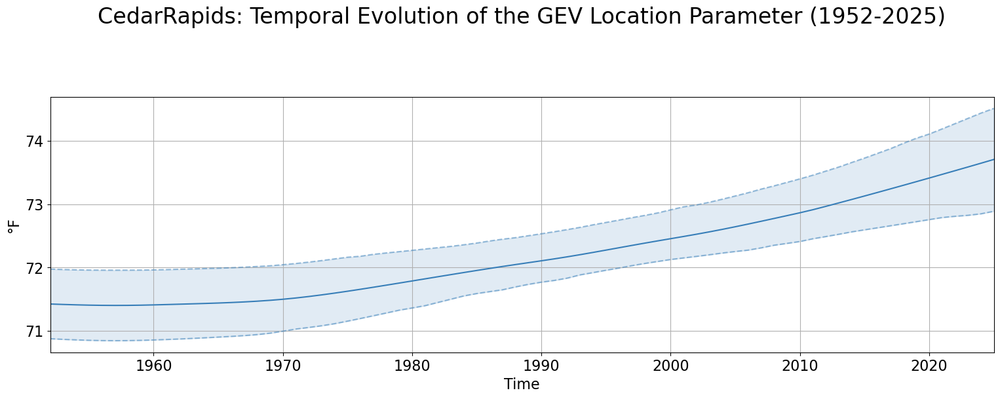

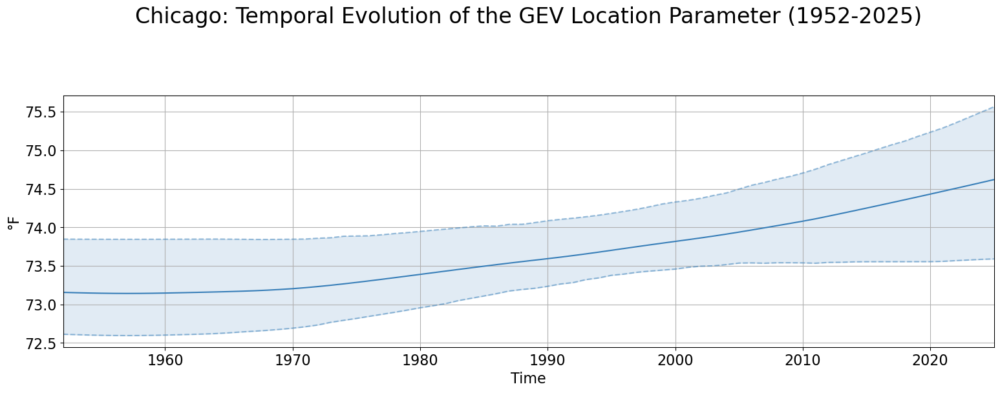

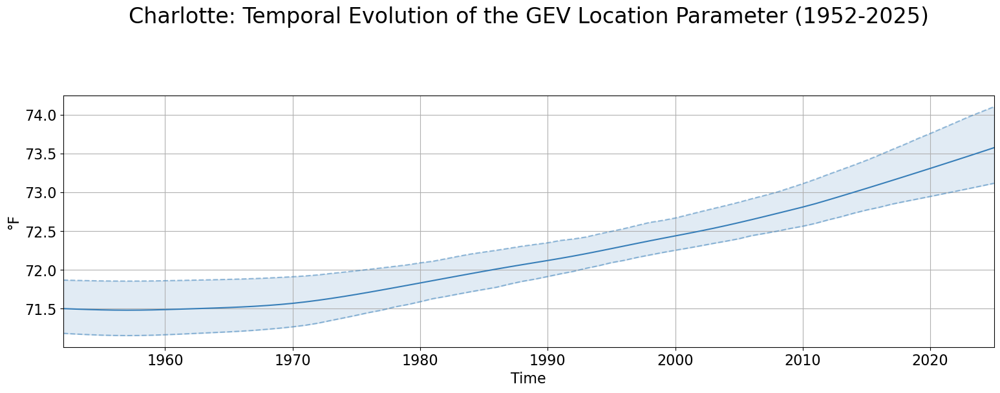

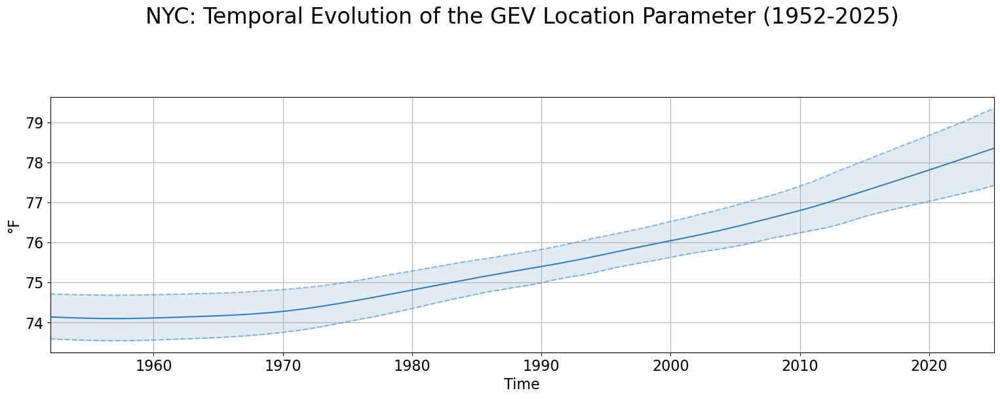

In [160]:
for ic in range(len(Tcity)):

  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(18,6))
  plt.subplots_adjust(bottom=0.1,left=0.1, right=0.9,top=0.75,wspace=0.2)
  irp=0
  ax.plot(ds['time'],location.sel(lon=ptlon[ic],lat=ptlat[ic]),color=CB_color[irp])
  ax.plot(ds['time'],location_q.sel(lon=ptlon[ic],lat=ptlat[ic],quantile=0.95),color=CB_color[irp],ls='--',alpha=0.5)
  ax.plot(ds['time'],location_q.sel(lon=ptlon[ic],lat=ptlat[ic],quantile=0.05),color=CB_color[irp],ls='--',alpha=0.5)
  ax.fill_between(ds['time'],location_q.sel(lon=ptlon[ic],lat=ptlat[ic],quantile=0.05),\
    location_q.sel(lon=ptlon[ic],lat=ptlat[ic],quantile=0.95),color=CB_color[irp],alpha=0.15)
    
  ax.tick_params(labelsize=16)
  ax.grid(True)
  ax.set_ylabel(f'{units}',fontsize=16) 
  ax.set_xlim(ds['time'][0],ds['time'][-1]) 
  ax.set_xlabel('Time',fontsize=16)

  #plt.legend(loc='center',ncol=len(return_periods),bbox_to_anchor=(-0.12,1.05),fontsize=12)
  plt.suptitle(f'{Tcity[ic]}: Temporal Evolution of the GEV Location Parameter ({yearb}-{yeare})',fontsize=24)
  plt.show()

*Time series of the estimated location parameter ($\mu$) of the nonstationary generalized extreme value (GEV) model for selected cities during 1952-2025. The solid line shows the fitted location parameter, while the shaded region denotes the 5th to 95th percentile bootstrap confidence interval. The location parameter represents the central tendency of the TNx1 extreme-value distribution and its temporal evolution reflects changes in the magnitude of extreme temperature events. Units are °F.*

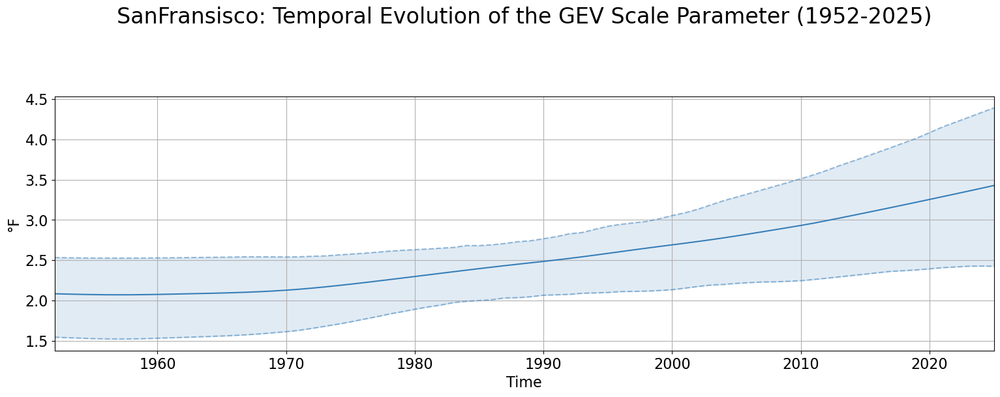

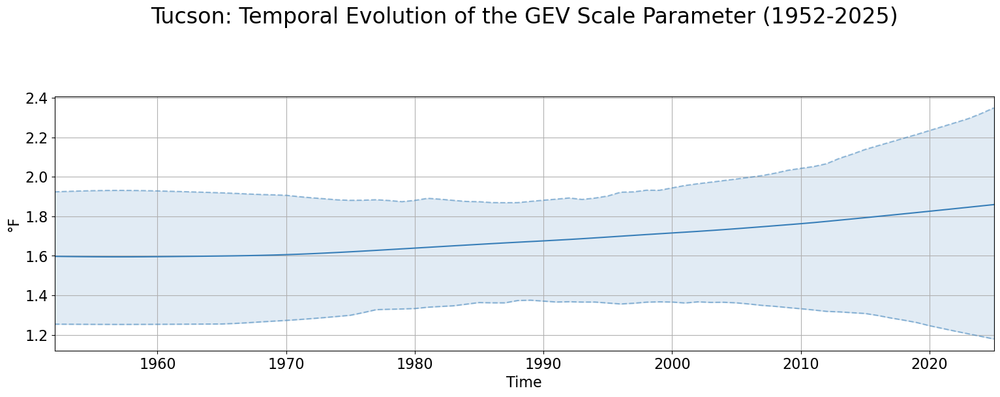

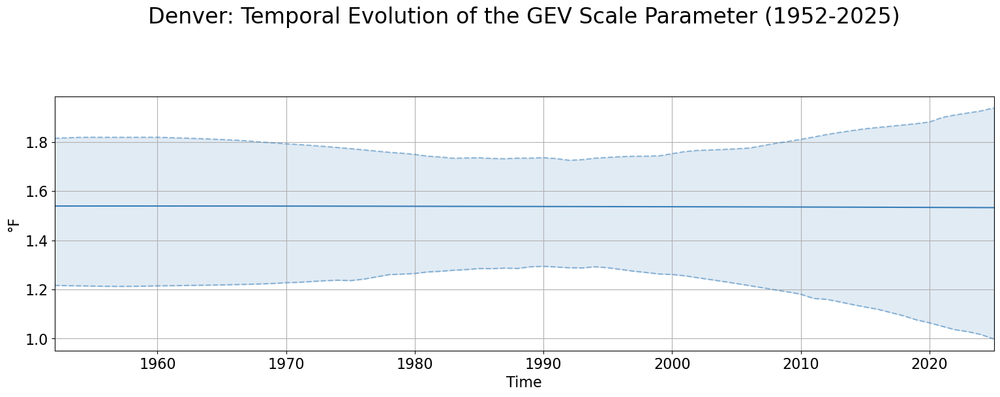

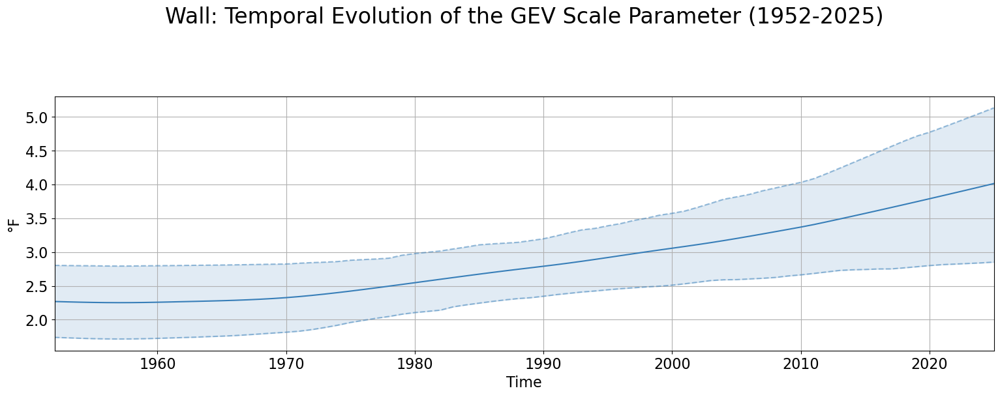

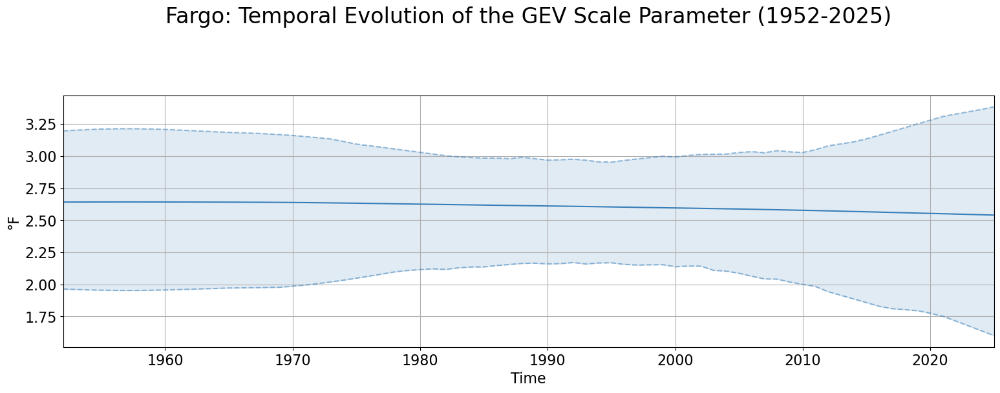

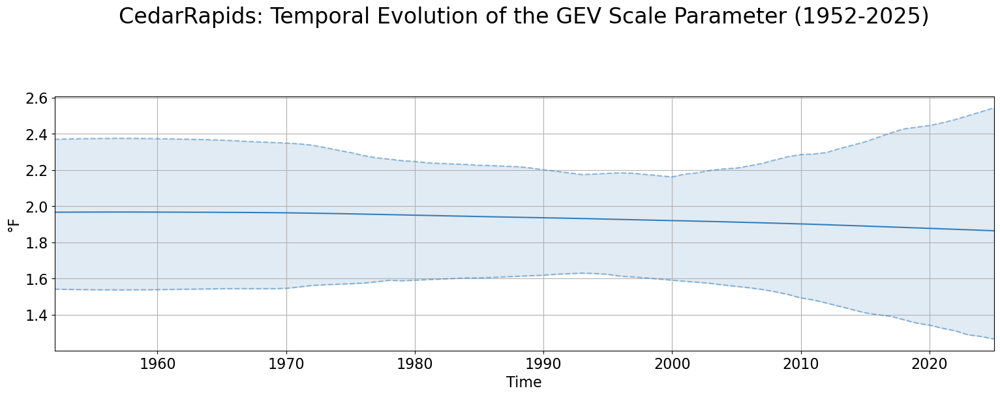

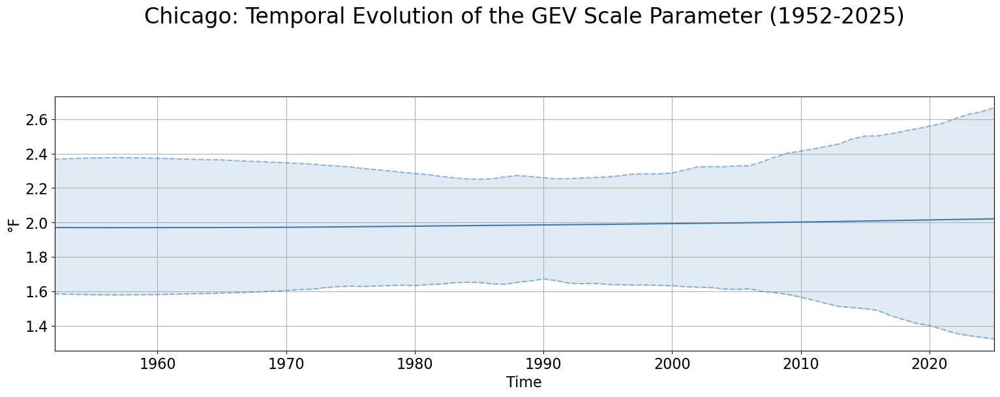

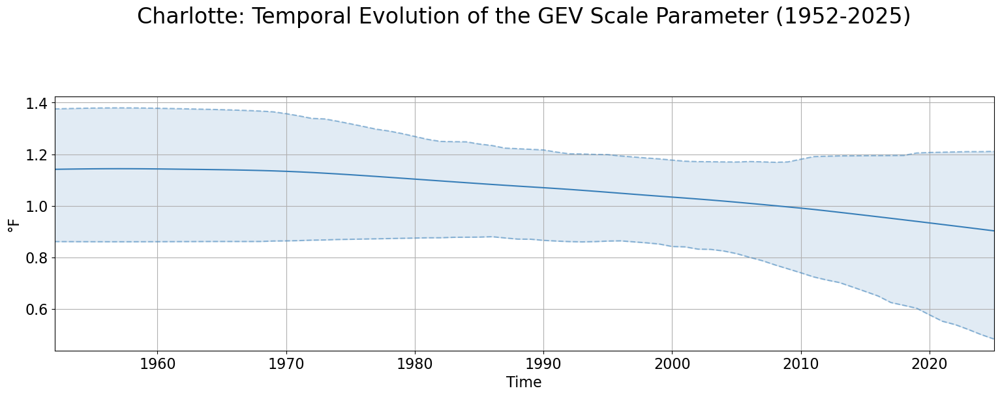

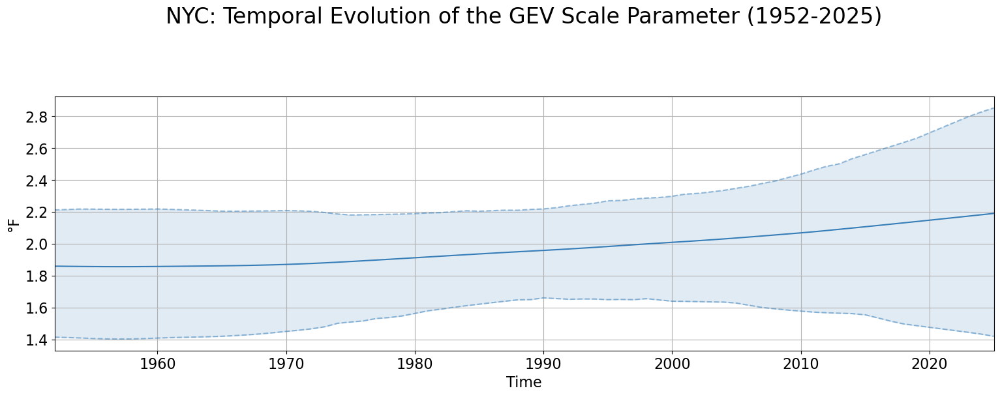

In [161]:
for ic in range(len(Tcity)):

  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(18,6))
  plt.subplots_adjust(bottom=0.1,left=0.1, right=0.9,top=0.75,wspace=0.2)
  irp=0
  ax.plot(ds['time'],scale.sel(lon=ptlon[ic],lat=ptlat[ic]),color=CB_color[irp])
  ax.plot(ds['time'],scale_q.sel(lon=ptlon[ic],lat=ptlat[ic],quantile=0.95),color=CB_color[irp],ls='--',alpha=0.5)
  ax.plot(ds['time'],scale_q.sel(lon=ptlon[ic],lat=ptlat[ic],quantile=0.05),color=CB_color[irp],ls='--',alpha=0.5)
  ax.fill_between(ds['time'],scale_q.sel(lon=ptlon[ic],lat=ptlat[ic],quantile=0.05),\
    scale_q.sel(lon=ptlon[ic],lat=ptlat[ic],quantile=0.95),color=CB_color[irp],alpha=0.15)
    
  ax.tick_params(labelsize=16)
  ax.grid(True)
  ax.set_ylabel(f'{units}',fontsize=16) 
  ax.set_xlim(ds['time'][0],ds['time'][-1]) 
  ax.set_xlabel('Time',fontsize=16)

  #plt.legend(loc='center',ncol=len(return_periods),bbox_to_anchor=(-0.12,1.05),fontsize=12)
  plt.suptitle(f'{Tcity[ic]}: Temporal Evolution of the GEV Scale Parameter ({yearb}-{yeare})',fontsize=24)
  plt.show()

*Time series of the estimated scale parameter ($\sigma$) of the nonstationary generalized extreme value (GEV) model for selected cities during 1952-2025. The solid line shows the fitted scale parameter, while the shaded region denotes the 5th to 95th percentile bootstrap confidence interval. The scale parameter represents the spread of the TNx1 extreme-value distribution, and its temporal evolution reflects changes in the variability of extreme temperature events. Units are °F.*

## Step 5: Technical notes

### Scoring formulas

- CRPS for predictive CDF $F$ and observation $y$:

  $$\mathrm{CRPS}(F,y)=\int_{-\infty}^{\infty}(F(x)-\mathbf{1}_{\{x\ge y\}})^2\,dx.$$

- Squared Error (SE):

  $$\mathrm{SE}=(y-\mu)^2.$$

- Dawid–Sebastiani Score (DSS):

  $$\mathrm{DSS}=\frac{(y-\mu)^2}{\sigma^2}+2\log\sigma.$$
